# **Tiamat**
Projeto Final - Aprendizado de Máquina

Aluno: Caio Guimarães Marino - T26 <br> Docente: Daniel Roberto Cassar

## **Introdução**

O Reino de Lumi está em alerta. Em uma de suas visões premonitórias, Vostrasirus Baba jurou de pé junto que um dragão lendário atacaria o reino neste semestre, e Vossa Iluminância, o Rei Milu Iluminarius MLVI, pediu que todos os membros das guildas se preparassem. A criatura é o Tiamat, um dragão de múltiplas cabeças, e sua captura é o projeto final da disciplina de Aprendizado de Máquina.

Para capturá-lo, é preciso escolher um conjunto de dados que atenda às considerações do desafio, comparar o desempenho de pelo menos $3$ algoritmos/pipelines de aprendizado de máquina (sem contar o baseline) e testar pelo menos $100$ conjuntos de hiperparâmetros diferentes para cada um deles, utilizando o `optuna`. Por ser o projeto final, a entrega deve ser científica, onde deve seguir as boas práticas apresentadas na disciplina, apresentar os resultados de forma gráfica, discuti-los e demonstrar o entendimento e a aplicação prática dos conceitos vistos ao longo do semestre. Ela é feita em um repositório `git` com um `README` que guia o leitor, e este notebook é o principal arquivo do projeto e presente neste repositório.

#### **Descrição do dataset escolhido**

O dataset escolhido (*Superconductivity Data*) foi retirado do UCI Machine Learning Repository[1] e reúne $21263$ materiais supercondutores, cada um descrito por $81$ atributos numéricos derivados exclusivamente da sua composição química. O objetivo deste conjunto de dados é prever a temperatura crítica (coluna `critical_temp`, em kelvin), ou seja, a temperatura abaixo do qual o material se torna supercondutor. <br> Os $81$ atributos se organizam como $8$ propriedades atômicas $\times$ $10$ estatísticas por propriedade $+$ o número de elementos do material. Como cada material possui uma quantidade diferente de elementos químicos, os autores do dataset resumiram cada propriedade dos elementos por meio de estatísticas, de modo que todos os materiais tenham o mesmo número de colunas. Dentre as propriedades atômicas presentes no dataset temos:
* Massa atômica (`atomic_mass`): massa total de prótons e nêutrons em repouso (em $u$)
* Primeira energia de ionização (`fie`): energia necessária para remover um elétron de valência (em $kJ/mol$)
* Raio atômico (`atomic_radius`): raio atômico calculado (em $pm$)
* Densidade (`Density`): densidade à temperatura e pressão padrão (em $kg/m³$)
* Afinidade eletrônica (`ElectronAffinity`): energia necessária para adicionar um elétron a um átomo neutro (em $kJ/mol$)
* Calor de fusão (`FusionHeat`): energia para passar de sólido a líquido sem mudar a temperatura (em $kJ/mol$)
* Condutividade térmica (`ThermalConductivity`): coeficiente de condutividade térmica (em $W/(m\cdot K)$)
* Valência (`Valence`): número típico de ligações químicas (sem unidade)

Para cada uma dessas propriedades, existem $10$ estatísticas calculadas sobre os elementos do material: média (`mean`), média geométrica (`gmean`), entropia (`entropy`), amplitude (`range`) e desvio padrão (`std`), cada uma em sua versão simples e em uma versão ponderada (começam com `wtd_`). <br> Os autores do dataset retirado do UCI Machine Learning Repository afirmam que o conjunto não possui valores ausentes.

Originalmente, o dataset contém dois arquivos, o principal `train.csv` e que será utilizado nesta tarefa, e o `unique_m.csv` que contém as fórmulas químicas para os $21263$ supercondutores do arquivo principal. Por escolha minha, será utilizado apenas o arquivo principal, visto que é o arquivo que contém os atributos e o target de interesse.

## **A Captura**

Nas seções e células abaixo, será realizada a captura do Tiamat.

#### **Importação de módulos**

Na célula abaixo, serão importados os módulos que serão utilizados no decorrer da captura do Tiamat.

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler, MinMaxScaler, PolynomialFeatures
from sklearn.model_selection import GroupShuffleSplit
from sklearn.dummy import DummyRegressor
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.feature_selection import RFE
from sklearn.inspection import permutation_importance
import optuna
from optuna import create_study
from optuna.samplers import TPESampler, GridSampler
from functools import partial
import optuna.visualization as vis
from optuna.trial import TrialState

optuna.logging.set_verbosity(optuna.logging.WARNING) # Deixa o optuna menos verboso

### **Importação do dataset e Análise Exploratória**

A seguir, importaremos o dataset a partir do módulo `pandas`.

In [2]:
NOME_DATASET = "train.csv"

df = pd.read_csv(NOME_DATASET)
df

,number_of_elements,mean_atomic_mass,wtd_mean_atomic_mass,gmean_atomic_mass,wtd_gmean_atomic_mass,entropy_atomic_mass,wtd_entropy_atomic_mass,range_atomic_mass,wtd_range_atomic_mass,std_atomic_mass,...,wtd_mean_Valence,gmean_Valence,wtd_gmean_Valence,entropy_Valence,wtd_entropy_Valence,range_Valence,wtd_range_Valence,std_Valence,wtd_std_Valence,critical_temp
0,4,88.944468,57.862692,66.361592,36.116612,1.181795,1.062396,122.90607,31.794921,51.968828,...,2.257143,2.213364,2.219783,1.368922,1.066221,1,1.085714,0.433013,0.437059,29.00
1,5,92.729214,58.518416,73.132787,36.396602,1.449309,1.057755,122.90607,36.161939,47.094633,...,2.257143,1.888175,2.210679,1.557113,1.047221,2,1.128571,0.632456,0.468606,26.00
2,4,88.944468,57.885242,66.361592,36.122509,1.181795,0.975980,122.90607,35.741099,51.968828,...,2.271429,2.213364,2.232679,1.368922,1.029175,1,1.114286,0.433013,0.444697,19.00
3,4,88.944468,57.873967,66.361592,36.119560,1.181795,1.022291,122.90607,33.768010,51.968828,...,2.264286,2.213364,2.226222,1.368922,1.048834,1,1.100000,0.433013,0.440952,22.00
4,4,88.944468,57.840143,66.361592,36.110716,1.181795,1.129224,122.90607,27.848743,51.968828,...,2.242857,2.213364,2.206963,1.368922,1.096052,1,1.057143,0.433013,0.428809,23.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21258,4,106.957877,53.095769,82.515384,43.135565,1.177145,1.254119,146.88130,15.504479,65.764081,...,3.555556,3.223710,3.519911,1.377820,0.913658,1,2.168889,0.433013,0.496904,2.44
21259,5,92.266740,49.021367,64.812662,32.867748,1.323287,1.571630,188.38390,7.353333,69.232655,...,2.047619,2.168944,2.038991,1.594167,1.337246,1,0.904762,0.400000,0.212959,122.10
21260,2,99.663190,95.609104,99.433882,95.464320,0.690847,0.530198,13.51362,53.041104,6.756810,...,4.800000,4.472136,4.781762,0.686962,0.450561,1,3.200000,0.500000,0.400000,1.98
21261,2,99.663190,97.095602,99.433882,96.901083,0.690847,0.640883,13.51362,31.115202,6.756810,...,4.690000,4.472136,4.665819,0.686962,0.577601,1,2.210000,0.500000,0.462493,1.84


Como o dataset possui $21263$ exemplos e $82$ colunas, fica inviável analisá-lo mostrando ele inteiro. Portanto, vamos analisar primeiramente se não há, realmente, valores ausentes e se há linhas duplicadas, para realizarmos posteriormente uma análise descritiva dos dados.

Vamos verificar se realmente não há valores ausentes no dataset utilizando o método `.isna()` do `pandas`:

In [3]:
contar_NaN = df.isna().sum() # Verificando se há NaN e somando por coluna
contar_NaN.sort_values()

number_of_elements       0
mean_atomic_mass         0
wtd_mean_atomic_mass     0
gmean_atomic_mass        0
wtd_gmean_atomic_mass    0
                        ..
range_Valence            0
wtd_range_Valence        0
std_Valence              0
wtd_std_Valence          0
critical_temp            0
Length: 82, dtype: int64

Com isso, podemos seguir tranquilamente quanto à presença de dados ausentes, visto que verificamos que realmente não há colunas com dados faltantes. Agora, vamos verificar se há linhas duplicadas no dataset.

Para isso, vamos contar quantas linhas duplicadas existem utilizando `.duplicated()` do `pandas`:

In [4]:
contar_duplicadas = df.duplicated().sum() # Verificando se a linha é duplicada e somando a quantidade de duplicadas
contar_duplicadas

np.int64(66)

A partir da célula acima podemos concluir que existem 66 linhas duplicadas, o que é algo que atrapalha a análise exploratória e a posterior análise dos algoritmos/pipelines que faremos, visto que cópias idênticas poderiam cairiam em treino e teste, o que aumentaria o desempenho do modelo. Ou seja, devemos tratar esses dados.

#### **Tratamento de dados**

Para retirar as linhas duplicadas do conjunto de dados, vamos filtrar o dataframe:

In [5]:
df_filtrado = df.drop_duplicates().reset_index(drop=True) # Filtra o dataframe mantendo somente as linhas únicas
# e reorganiza os índices 
df_filtrado

,number_of_elements,mean_atomic_mass,wtd_mean_atomic_mass,gmean_atomic_mass,wtd_gmean_atomic_mass,entropy_atomic_mass,wtd_entropy_atomic_mass,range_atomic_mass,wtd_range_atomic_mass,std_atomic_mass,...,wtd_mean_Valence,gmean_Valence,wtd_gmean_Valence,entropy_Valence,wtd_entropy_Valence,range_Valence,wtd_range_Valence,std_Valence,wtd_std_Valence,critical_temp
0,4,88.944468,57.862692,66.361592,36.116612,1.181795,1.062396,122.90607,31.794921,51.968828,...,2.257143,2.213364,2.219783,1.368922,1.066221,1,1.085714,0.433013,0.437059,29.00
1,5,92.729214,58.518416,73.132787,36.396602,1.449309,1.057755,122.90607,36.161939,47.094633,...,2.257143,1.888175,2.210679,1.557113,1.047221,2,1.128571,0.632456,0.468606,26.00
2,4,88.944468,57.885242,66.361592,36.122509,1.181795,0.975980,122.90607,35.741099,51.968828,...,2.271429,2.213364,2.232679,1.368922,1.029175,1,1.114286,0.433013,0.444697,19.00
3,4,88.944468,57.873967,66.361592,36.119560,1.181795,1.022291,122.90607,33.768010,51.968828,...,2.264286,2.213364,2.226222,1.368922,1.048834,1,1.100000,0.433013,0.440952,22.00
4,4,88.944468,57.840143,66.361592,36.110716,1.181795,1.129224,122.90607,27.848743,51.968828,...,2.242857,2.213364,2.206963,1.368922,1.096052,1,1.057143,0.433013,0.428809,23.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21192,4,106.957877,53.095769,82.515384,43.135565,1.177145,1.254119,146.88130,15.504479,65.764081,...,3.555556,3.223710,3.519911,1.377820,0.913658,1,2.168889,0.433013,0.496904,2.44
21193,5,92.266740,49.021367,64.812662,32.867748,1.323287,1.571630,188.38390,7.353333,69.232655,...,2.047619,2.168944,2.038991,1.594167,1.337246,1,0.904762,0.400000,0.212959,122.10
21194,2,99.663190,95.609104,99.433882,95.464320,0.690847,0.530198,13.51362,53.041104,6.756810,...,4.800000,4.472136,4.781762,0.686962,0.450561,1,3.200000,0.500000,0.400000,1.98
21195,2,99.663190,97.095602,99.433882,96.901083,0.690847,0.640883,13.51362,31.115202,6.756810,...,4.690000,4.472136,4.665819,0.686962,0.577601,1,2.210000,0.500000,0.462493,1.84


O dataframe acima agora não apresenta mais linhas duplicadas e já pode ser utilizado para realizar a análise exploratória.

#### **Computando estatísticas descritivas**

Antes de começar a análise descritiva dos dados, na célula abaixo será separado os atributos e o target:

In [6]:
TARGET = "critical_temp"

X = df_filtrado.drop(columns=TARGET) # Atributos
y = df_filtrado[TARGET] # Target

A seguir, serão computadas estatísticas descritivas do conjunto de dados utilizado o método `.describe()` do pandas.

*OBS.: Como o dataset é muito grande e conta com 81 atributos, a tabela inteira do describe ficaria muito grande e não exibiria as informações de todas as colunas. Por este motivo, a tabela será resumida mostrando como a média, desvio padrão, o mínimo e o máximo variam entre os atributos.*

In [7]:
resumo = X.describe().T
resumo[["mean", "std", "min", "max"]].describe().round(2)

,mean,std,min,max
count,81.00,81.00,81.00,81.00
mean,540.21,321.64,21.38,2153.35
std,1469.37,919.63,81.88,6037.19
min,0.54,0.29,0.00,1.61
25%,3.05,1.04,0.00,7.00
50%,51.29,25.27,0.00,207.97
75%,134.64,58.68,1.00,349.00
max,8673.26,4093.01,375.50,22590.00


Analisando a tabela de describe acima é possível perceber que os atributos estão em escalas muito diferentes. Entre os $81$ atributos, a média varia de $0.54$ a $8673.26$ e o desvio padrão varia de $0.29$ a $4093.01$, uma diferença de cerca de quatro ordens de grandeza. Além disso, enquanto metade dos atributos tem valor máximo abaixo de aproximadamente $208$, alguns chegam a mais de $22000$. Como modelos baseados em distância (como KNN) e modelos lineares são sensíveis à escala dos atributos, será necessário normalizar os dados para esses modelos. Já modelos baseados em árvores, como árvore de decisão e floresta aleatória, não dependem da escala e não exigem essa etapa.

Ordenando a tabela `resumo` pelo desvio padrão e juntando as 3 primeiras linhas (atributos com menor desvio padrão) com as 3 últimas (os de maior desvio padrão), é possível obter a seguinte tabela:

In [8]:
resumo_sort_std = resumo.sort_values("std") # Ordenando tabela pelo desvio padrão
pd.concat([resumo_sort_std.head(3), resumo_sort_std.tail(3)])[["mean", "std", "min", "max"]].round(2)

,mean,std,min,max
wtd_entropy_ElectronAffinity,0.77,0.29,0.00,1.68
wtd_entropy_ThermalConductivity,0.54,0.32,0.00,1.61
wtd_entropy_Density,0.86,0.32,0.00,1.70
gmean_Density,3448.17,3697.03,1.43,22590.00
wtd_gmean_Density,3104.48,3970.07,0.69,22590.00
range_Density,8673.26,4093.01,0.00,22588.57


Observando a tabela acima, nota-se uma diferença evidente nos extremos ao ordenar pelo desvio padrão, onde os atributos com menor dispersão são entropias ponderadas, como `wtd_entropy_ElectronAffinity` (desvio padrão de $0.29$), enquanto os de maior dispersão são estatísticas da densidade, como `range_Density` (desvio padrão de $4093.01$). Sem normalização, no KNN os atributos de densidade dominariam o cálculo da distância, tornando a contribuição das entropias praticamente irrelevante.

Agora, vamos olhar para a variável que queremos prever, o target que definimos anteriormente (y; `critical_temp`):

In [9]:
y.describe().round(2)

count    21197.00
mean        34.49
std         34.28
min          0.00
25%          5.38
50%         20.00
75%         63.00
max        185.00
Name: critical_temp, dtype: float64

Analisando o describe acima, percebe-se que a temperatura crítica apresenta média de $34.49\ K$ e mediana de $20\ K$. Essa diferença entre a média e a mediana (com média maior), juntamente com o fato do desvio padrão ($34.28\ K$) ser muito próximo da média, indica uma assimetria com distribuição puxada para a direita, apresentando metade dos materiais com temperatura crítica de até $20\ K$, enquanto os valores acima do $3º$ quartil de $63\ K$ se estendem até $185\ K$. Com isso, podemos concluir que os materiais de alta temperatura crítica são uma minoria e se espalham por uma faixa grande, o que provavelmente vai dificultar a previsão nessa região.

Vamos calcular a assimetria do nosso target utilizando o método `.skew()` do `pandas`:

In [10]:
print(f'Assimetria do target: {y.skew():.2f}')
print(f'\nMateriais com Tc <= 10 K: {(y <= 10).mean():.1%}')
print(f'\nMateriais com Tc >= 77 K: {(y >= 77).mean():.1%}')

Assimetria do target: 0.86

Materiais com Tc <= 10 K: 36.8%

Materiais com Tc >= 77 K: 18.6%


Com os números acima podemos confirmar que há uma assimetria positiva moderada. Cerca de $36.8\%$ dos materiais têm temperatura crítica de até $10\ K$, enquanto $18.6\%$ dos materiais têm $T_c$ de pelo menos $77\ K$, o ponto de ebulição do nitrogênio líquido. Isso evidencia ainda mais a distribuição concentrada em valores baixos concluída anteriormente, com uma cauda que se estende até $185\ K$.

Vamos analisar graficamente essa distribuição do target com um histograma gerado com auxílio do Claude (Anthropic):

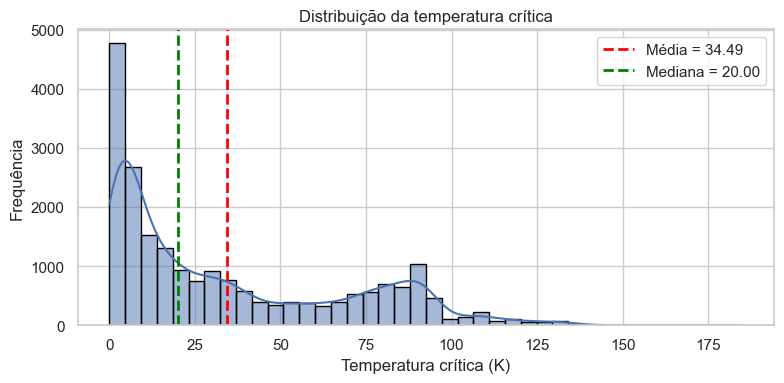

In [11]:
sns.set_theme(style="whitegrid")
fig, eixo = plt.subplots(figsize=(8, 4))
sns.histplot(y, bins=40, kde=True, edgecolor="black", ax=eixo)
eixo.axvline(y.mean(), color="red", linestyle="--", linewidth=2, label=f"Média = {(y.mean()):.2f}")
eixo.axvline(y.median(), color="green", linestyle="--", linewidth=2, label=f"Mediana = {(y.median()):.2f}")
eixo.set_xlabel("Temperatura crítica (K)")
eixo.set_ylabel("Frequência")
eixo.set_title("Distribuição da temperatura crítica")
eixo.legend()

plt.tight_layout()
plt.show()

Observando o histograma da temperatura crítica acima, é possível notar uma distribuição bimodal, com um pico acentuado em valores muito baixos (a primeira faixa) concentra mais de $4500$ materiais) e uma segunda elevação por volta de $85$ a $90\ K$, separados por uma região de menor densidade. Além disso, nota-se que acima de $100\ K$ há poucos materiais. A média ($34.49\ K$) cai justamente no vale entre os dois grupos, e a mediana ($20\ K$) na descida do primeiro pico, de modo que a média não é representativa de nenhum dos dois grupos. Isso sugere que o conjunto de dados reúne materiais de naturezas distintas e que um bom modelo precisará dintingui-los.

#### **Medindo relação entre atributos e target**

É extremamente interessante sabermos quais atributos "andam junto" com a temperatura crítica, por exemplo se um atributo é alto a $T_c$ costuma ser alta (ou baixa). Isso pode ser calculado a partir da correlação de Pearson, que é um número entre $-1$ e $1$ que resume a relação entre dois conjuntos de valores, onde:
* Perto de $1$: quando um sobe, o outro tende a subir.
* Perto de $-1$: quando um sobe, o outro tende a descer.
* Perto de $0$: não existe uma relação linear entre os conjuntos de valores.

Sabendo disso, vamos calcular a correlação de Pearson entre atributos e target usando o `pandas`:

In [12]:
m_corr = df_filtrado.corr() # Calcula a matriz de correlação de todas as colunas, incluindo o target
corr = m_corr[TARGET].drop(TARGET) # Pega a correlação de cada atributo com o target e tira a correlação
# do target com ele mesmo
ordena_corr = corr.abs().sort_values(ascending=False).index # Ordena a correlação de forma decrescente
# comparando só a força da correlação e guardando só os nomes dos atributos 
corr[ordena_corr].head(10).round(2) # Pega a lista original e reorganiza na ordem de ordena_corr

wtd_std_ThermalConductivity    0.72
range_ThermalConductivity      0.69
range_atomic_radius            0.65
std_ThermalConductivity        0.65
wtd_mean_Valence              -0.63
wtd_entropy_atomic_mass        0.63
wtd_gmean_Valence             -0.62
wtd_entropy_atomic_radius      0.60
number_of_elements             0.60
range_fie                      0.60
Name: critical_temp, dtype: float64

Com a tabela acima, podemos concluir que os atributos mais correlacionados com a temperatura crítica são, em sua maioria, medidas de dispersão (amplitude e desvio padrão) das propriedades atômicas dos elementos do material, como `wtd_std_ThermalConductivity` ($r = 0.72$), `range_ThermalConductivity` ($r = 0.69$) e `range_atomic_radius` ($r = 0.65$). Isso dá a entender que materiais compostos por elementos com propriedades muito diferentes entre si tendem a ter $T_c$ maior, mas isso é apenas uma hipótese, visto que correlação não implica causa. Já a valência média ponderada (`wtd_mean_Valence`) tem correlação negativa ($-0.63$). Nenhum atributo isolado ultrapassa de $0.75$ de correlação, e vários dos mais correlacionados são variantes da mesma propriedade, o que indica redundância entre eles.

Vamos observar graficamente essa correlação, analisando os dois primeiros atributos contra o target:

[Text(0.5, 0, 'wtd_std_ThermalConductivity'),
 Text(0, 0.5, 'Temperatura crítica (K)')]

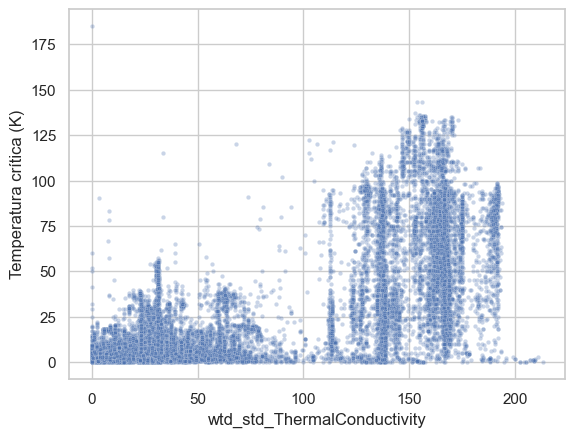

In [13]:
eixo = sns.scatterplot(
    df_filtrado,
    x="wtd_std_ThermalConductivity",
    y=TARGET,
    alpha=0.3,
    s=10,
)
eixo.set(xlabel="wtd_std_ThermalConductivity", ylabel="Temperatura crítica (K)")

[Text(0.5, 0, 'range_ThermalConductivity'),
 Text(0, 0.5, 'Temperatura crítica (K)')]

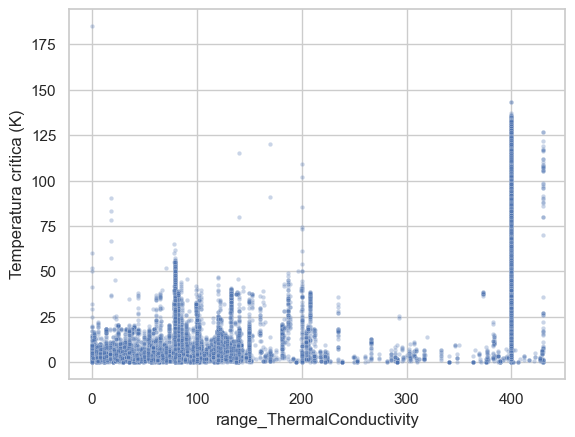

In [14]:
eixo = sns.scatterplot(
    df_filtrado,
    x="range_ThermalConductivity",
    y=TARGET,
    alpha=0.3,
    s=10,
)
eixo.set(xlabel="range_ThermalConductivity", ylabel="Temperatura crítica (K)")

*OBS.: gráficos gerados a partir de uma adaptação de um gráfico feito pelo Prof. Dr. Daniel Roberto Cassar no notebook* ***ATP-203 3.0 - Modelo linear e baseline*** [2]*.*

Analisando os gráficos de dispersão acima, percebe-se que a relação entre esses atributos e a temperatura crítica não é linear. Para `wtd_std_ThermalConductivity`, os materiais se dividem em duas regiões, uma onde abaixo de $\sim 100$ a $T_c$ é quase sempre baixa e outra onde acima de $\sim 110$ ela é mais alta e muito dispersa, com poucos materiais entre as duas. Na região de valores altos, materiais com valores quase idênticos do atributo apresentam $T_c$ muito diferentes. Em `range_ThermalConductivity`, metade dos materiais se concentra em torno de $400$. <br><br> Assim, a correlação de $0.72$ e $0.69$ reflete principalmente a separação entre os dois grupos observados no histograma do target, o que sugere que modelos lineares simples terão dificuldade e que modelos não lineares tendem a ser mais adequados.

#### **Multicolinearidade entre atributos**

É extremamente importante verificar a multicolinearidade entre os atributos, principalmente no caso deste conjunto de dados em que os $81$ atributos são variantes das mesmas propriedades e já verificou-se que vários dos mais correlacionados com o target são repetidos. Em outras palavras, a multicolinearidade é a redundância entre atributos, onde dois atributos muito correlacionados carregam quase a mesma informação.

Para analisar a multicolinearidade entre atributos, vamos analisar a matriz de correlação em um mapa de calor e contar quantos pares de atributos são muito parecidos.

A célula de código abaixo gera um mapa de calor da matriz de correlação:

[Text(0.5, 47.24444444444444, 'Atributos'),
 Text(101.6444444444445, 0.5, 'Atributos'),
 Text(0.5, 1.0, 'Matriz de correlação entre os atributos')]

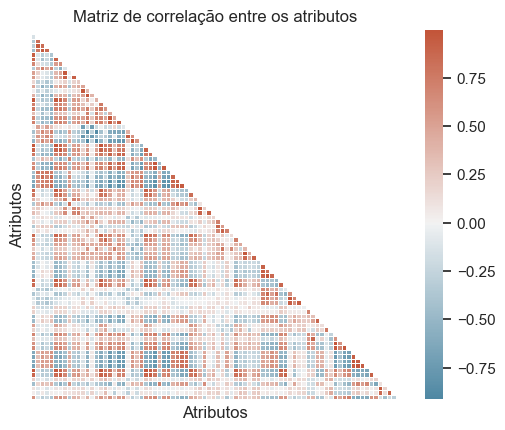

In [15]:
sns.set_theme(style="white")

mascara = np.triu(np.ones_like(m_corr, dtype=bool))
mapa_de_cor = sns.diverging_palette(230, 20, as_cmap=True)

eixo = sns.heatmap(
    m_corr,
    mask=mascara,
    cmap=mapa_de_cor,
    center=0,
    square=True,
    xticklabels=False, # Nome dos ticks removidos pois estavam ilegíveis devido à grande quantidade
    yticklabels=False,
    linewidths=0.5
)

eixo.set(xlabel="Atributos", ylabel="Atributos", title="Matriz de correlação entre os atributos")

*OBS.: gráfico gerado a partir de uma adaptação de um gráfico feito pelo Prof. Dr. Daniel Roberto Cassar no notebook* ***ATP-203 8.0 - Redução de dimensionalidade com PCA*** [3]*.*

Como o mapa da a impressão, vamos contar os pares muito correlacionados para obter o número:

In [16]:
# OBS.: ESTA CÉLULA DE CÓDIGO FOI ADAPTADA DE UM CÓDIGO GERADO PELO CLAUDE

LIMIAR_CORR = [0.7, 0.9, 0.95]

corr_superior = np.triu(m_corr.abs().to_numpy(), k=1)
total_pares = X.shape[1] * (X.shape[1] - 1) // 2

for limiar in LIMIAR_CORR:
    n_pares = (corr_superior > limiar).sum()

    print(f"Pares de atributos com módulo da correlação > {limiar}: {n_pares} de {total_pares} ({(n_pares/total_pares)*100:.1f}%)")

Pares de atributos com módulo da correlação > 0.7: 298 de 3240 (9.2%)
Pares de atributos com módulo da correlação > 0.9: 74 de 3240 (2.3%)
Pares de atributos com módulo da correlação > 0.95: 30 de 3240 (0.9%)


Analisando a matriz de correlação e os pares muito correlacionados calculados acima, é evidente que há uma redundância considerável entre os atributos, com $298$ dos $3240$ pares possíveis ($9.2\%$) tendo força de correlação acima de $0.7$, $74$ ($2.3\%$) acima de $0.9$ e $30$ ($0.9\%$) acima de $0.95$. Muitos desses pares são variantes da mesma propriedade (por exemplo, a média e a média geométrica ponderadas da valência), o que é esperado pela forma como os atributos foram construídos. Essa multicolinearidade justifica testar redução de dimensionalidade ou seleção de atributos.

Sem remover nenhum atributo e sem realizar nenhuma seleção, vamos quantificar a redundância de cada atributo em relação aos demais a partir do cálculo do fator de inflação da variância (VIF). <br> Observe esse cálculo na célula abaixo:

In [17]:
X_com_constante = sm.add_constant(X) # necessário para o VIF do statsmodels

vif = pd.Series(
    [variance_inflation_factor(X_com_constante.values, i) for i in range(X_com_constante.shape[1])],
    index=X_com_constante.columns,
).drop("const")  # ignora o VIF da constante

print(f'Atributos com VIF > 5: {(vif > 5).sum()} de {len(vif)}')
print(f'\nAtributos com VIF > 10: {(vif > 10).sum()} de {len(vif)}')
print(f'\nVIF máximo: {vif.max():.2f}')
print(f'\nVIF mínimo: {vif.min():.2f}')

vif.sort_values(ascending=False).head(10).round(2)

Atributos com VIF > 5: 81 de 81

Atributos com VIF > 10: 81 de 81

VIF máximo: 8417.20

VIF mínimo: 17.80


wtd_mean_fie               8417.20
wtd_gmean_fie              5737.97
wtd_mean_Valence           5041.03
wtd_gmean_atomic_radius    4903.28
wtd_gmean_Valence          4309.40
entropy_fie                4075.10
wtd_mean_atomic_radius     3304.41
entropy_atomic_radius      2990.28
mean_Valence               2728.54
gmean_Valence              2437.86
dtype: float64

*OBS.: célula de código retirada e adaptada do notebook* ***ATP-203 8.1 - Seleção de atributos*** [4] *feito pelo Prof. Dr. Daniel Roberto Cassar.*

Com os números acima, percebe-se que o VIF calculado para os $81$ atributos mostra uma multicolinearidade muito alta, com todos os atributos apresentando VIF acima de $10$, sendo o menor deles $17.8$. O maior VIF registrado foi de $8417.20$ (`wtd_mean_fie`), o que equivale a um coeficiente de determinação ($R^2$) de aproximadamente $0.9999$ (da fórmula $\mathrm{VIF} = 1 / (1 - R^2)$) na regressão desse atributo sobre os demais. Os maiores valores concentram-se em médias e médias geométricas da valência, da primeira energia de ionização e do raio atômico. Esse resultado indica que, em modelos lineares sem regularização (sem penalização de coeficientes), as estimativas dos coeficientes seriam muito instáveis, e motiva o uso de redução de dimensionalidade ou de seleção de atributos.

#### **Conclusão da análise exploratória**

Após uma análise completa do conjunto de dados foi possível perceber que o conjunto não possui valores ausentes, e as $66$ linhas duplicadas foram removidas, restando $21197$ materiais. Notou-se que os atributos estão em escalas muito diferentes (desvios padrão de $0.29$ a $4093$), então será necessário normalizá-los para os modelos sensíveis à escala, como KNN e a regressão linear. Observou-se também que a temperatura crítica tem distribuição bimodal, com a média ($34.49\ K$) caindo no vale entre os dois grupos, o que indica que o modelo precisa distinguir os grupos. Além disso, concluiu-se que a relação entre os atributos e o target não é linear (os gráficos de dispersão mostram regiões distintas), o que pode favorecer modelos não lineares. Há ainda uma forte multicolinearidade ($74$ pares com força de correlação $> 0.9$ e VIF acima de $10$ em todos os $81$ atributos), o que motiva PCA ou seleção de atributos.

### **Modelagem**

Nas seções e células abaixo, faremos as divisões em treino e teste, a otimização de hiperparâmetros com `optuna` e a modelagem dos diferentes algoritmos.

#### **Divisão em treino e teste por grupos (`KMeans` + `GroupShuffleSplit`)**

Materiais muito parecidos (por exemplo, da mesma família química) têm atributos quase idênticos e temperaturas críticas muito semelhantes. Se eles forem separados aleatoriamente entre treino e teste, o modelo "reconhece" no treino versões iguais dos materiais do teste, e o erro medido fica menor do que seria para materiais realmente novos (este é o chamada vazamento de dados por redundância [5]), fazendo com que o modelo se pareça bom quando ele, na verdade, não é. <br><br> Para evitar isso, usamos o `GroupShuffleSplit`, que mantém todos os materiais de um mesmo grupo ou no treino ou no teste. Com isso, resta apenas definir os grupos. A estratégia de arredondar os atributos e agrupar linhas iguais foi testada neste notebook e não funcionaria bem aqui, pois o arredondamento gerou $15089$ (observe a célula de código abaixo) grupos para $21197$ materiais, quase um por material, de modo que o split resultante geraria grupos pequenos demais para separar materiais semelhantes.

In [18]:
ATRIBUTOS = X.columns.tolist()

num_grupos_arredond = df_filtrado[ATRIBUTOS].round(0).groupby(ATRIBUTOS).ngroup().nunique()

print(f'O número de grupos obtidos por arredondamento e agrupamento de linhas iguais é {num_grupos_arredond} para {df_filtrado.shape[0]} materiais.')

O número de grupos obtidos por arredondamento e agrupamento de linhas iguais é 15089 para 21197 materiais.


Será utilizado então o `KMeans` [6], um algoritmo de agrupamento que não usa o target. Dado um número $K$ de grupos, ele escolhe $K$ centros e repete dois passos:
1. associa cada material ao centro mais próximo;
2. e recalcula cada centro como a média dos materiais do seu grupo, até a convergência.

Assim, materiais com atributos semelhantes ficam no mesmo grupo. Como o `KMeans` usa distâncias, os atributos devem ser normalizados antes (apenas para formar os grupos).

Apesar de resolver o problema do vazamento de dados por redundância, o `KMeans` possui algumas limitações. Os grupos aproximam as famílias químicas (uma família pode ser dividida em dois grupos, ou duas famílias podem se juntar), e ele utiliza os atributos de todos os materiais, sem o target, antes da divisão.

Para este notebook, será adotado $K = 500$, o que fornece cerca de $42$ materiais por grupo (em média), que foi uma escolha feita mentalmente e sem ajuste pelo desempenho nos dados de teste.

Observe na célula abaixo a divisão em treino e teste:

In [19]:
SEMENTE_ALEATORIA = 11515
TAMANHO_TESTE = 0.2
NUM_GRUPOS = 500 # K

# Criando grupos de materiais parecidos
normalizador = StandardScaler()
X_normalizado = normalizador.fit_transform(df_filtrado[ATRIBUTOS])

grupos = KMeans(
    n_clusters=NUM_GRUPOS, n_init=1, random_state=SEMENTE_ALEATORIA
).fit_predict(X_normalizado)

# Dividindo por grupo
gss = GroupShuffleSplit(
    n_splits=1, test_size=TAMANHO_TESTE, random_state=SEMENTE_ALEATORIA
)

indices_treino, indices_teste = next(
    gss.split(df_filtrado[ATRIBUTOS], df_filtrado[TARGET], groups=grupos)
)

df_treino = df_filtrado.iloc[indices_treino]
df_teste = df_filtrado.iloc[indices_teste]

X_treino = df_treino.reindex(ATRIBUTOS, axis=1).values
y_treino = df_treino[TARGET].values

X_teste = df_teste.reindex(ATRIBUTOS, axis=1).values
y_teste = df_teste[TARGET].values

#### **O modelo baseline**

O modelo baseline é o modelo mais simples possível, o qual ignora todos os atributos e prevê sempre a mesma coisa, a média do target no treino (a moda em problemas de classificação). Ele é um modelo utilizado como referência para comparação com outros modelos e não deve ser utilizado para problemas reais. Qualquer modelo com um desempenho pior que o do baseline é um modelo ruim. Portanto, todos os modelos que serão implementados e treinados neste notebook devem bater o RMSE do baseline.

No caso do conjunto de dados presentes neste notebook, o baseline prevê sempre a média de `critical_temp` do treino e servirá de referência de desempenho para os demais modelos.

Na célula abaixo, será implementado o modelo baseline utilizando a função `DummyRegressor` do scikit-learn:

In [20]:
# Criando instância
modelo_baseline = DummyRegressor()
# Ajustando modelo aos dados
modelo_baseline.fit(X_treino, y_treino)

print(f"Valor previsto para todos os materiais: {modelo_baseline.constant_.item():.2f} K") # Média da
# temperatura crítica no treino. É o único valor que o baseline prevê para qualquer material

y_previsto_baseline = modelo_baseline.predict(X_teste)

RMSE_BASELINE = root_mean_squared_error(y_teste, y_previsto_baseline)

print(f"O RMSE do modelo baseline foi de {RMSE_BASELINE:.2f} K.")
print(f"Desvio padrão dos targets de teste: {y_teste.std():.2f} K")

Valor previsto para todos os materiais: 34.24 K
O RMSE do modelo baseline foi de 35.50 K.
Desvio padrão dos targets de teste: 35.48 K


Analisando o desempenho do modelo baseline acima, que prevê para todos os materiais a média da temperatura crítica do conjunto de treino ($34.24\ K$), obteve-se um RMSE de $35.50\ K$ no conjunto de teste, valor praticamente igual ao desvio padrão de `y_teste` ($35.48\ K$), como esperado para um modelo que ignora os atributos. Esse valor de RMSE obtido serve de referência pois, qualquer modelo com RMSE maior ou igual a $35.50\ K$ não aprendeu nada útil dos atributos.

#### **Estratégia de avaliação dos modelos**

Para tornar a comparação dos modelos justa, nesta seção será definido como será a avaliação de todos os modelos.

As quatro regras escolhidas para a avaliação dos modelos são:
1. O conjunto de testes só é usado, uma única vez, depois da otimização de cada algoritmo/pipeline para avaliar o modelo escolhido. Nenhuma decisão (hiperparâmetros, escolha entre pipelines) usa o teste, para evitar vazamento de dados [5].

2. A busca de hiperparâmetros é feita com o `optuna`, que avalia cada combinação pelo RMSE médio de uma validação cruzada de 5 folds, calculada apenas no conjunto de treino. Foi escolhido $5$ folds para manter viável o tempo de execução, já que cada pipeline será avaliado em 100 ou mais conjuntos de hiperparâmetros.

3. A validação cruzada é feita por grupos (`GroupKFold` [7, 8]), usando os mesmos grupos criados na divisão com `KMeans`. Assim, materiais parecidos nunca ficam em folds diferentes. Sem isso, a validação seria otimista e favoreceria modelos que "decoram" materiais quase idênticos aos do treino.

4. A métrica de desempenho escolhida é o `RMSE` (raiz do erro quadrático médio), pelo fato de estar na mesma unidade do target ($K$), o que facilita a interpretação, e por penalizar mais os erros grandes, relevantes para materiais de alta temperatura crítica, que são difíceis de prever.

#### **Validação cruzada**

**1. Grupos de treino e `GroupKFold`**

Na célula abaixo, prepararemos os grupos de treino utilizando os mesmos grupos criados na divisão feita com o `KMeans` e prepararemos o objeto de validação, que neste caso será o `GroupKFold`:

In [21]:
NUM_FOLDS = 5

grupos_treino = grupos[indices_treino] # Guarda os grupos dos materiais de treino
validacao = GroupKFold(n_splits=NUM_FOLDS) # Divisor que vai separar o treino em 5 partes 
# sem quebrar nenhum grupo

**2. Validação cruzada no baseline**

A célula a seguir mede o baseline com validação cruzada por grupos e fornece o RMSE de referência no mesmo protocolo que usaremos para os outros modelos.

In [22]:
metricas_baseline = cross_val_score(
    DummyRegressor(),
    X_treino,
    y_treino,
    groups=grupos_treino,
    cv=validacao,
    scoring="neg_root_mean_squared_error"
)

RMSE_BASELINE_CV = abs(metricas_baseline.mean())

print("RMSE por fold:", abs(metricas_baseline))
print(f'\nRMSE médio da validação cruzada: {RMSE_BASELINE_CV:.2f} K')

RMSE por fold: [35.02658824 32.48633312 32.81975558 35.54217508 33.9126994 ]

RMSE médio da validação cruzada: 33.96 K


Analisando os resultados acima, na validação cruzada por grupos com $5$ folds, o baseline obteve RMSE médio de $33.96\ K$, com valores entre $32.49\ K$ e $35.54\ K$ nos folds, o que ilustra a variabilidade da estimativa devido à composição de cada fold. No conjunto de teste, o RMSE do baseline foi de $35.50\ K$. Como esses valores servem de referência, uma diferença de aproximadamente $1\ K$ pode estar dentro da variação entre folds.

#### **Otimização de hiperparâmetros com `optuna` e criação de pipelines**

Nesta seção, serão implementados 5 pipelines de aprendizado de máquina testando, para cada um, pelo menos 100 conjuntos diferentes de hiperparâmetros escolhidos usando o módulo `optuna`. Em cada tentativa de otimização de hiperparâmetros, o optuna sugere uma combinação, o pipeline correspondente é avaliado por validação cruzada por grupos com $5$ folds (apenas no conjunto de treino) e o RMSE médio é devolvido ao optuna, que o usa para escolher as próximas combinações. Ao final, o melhor pipeline de cada algoritmo é treinado com todo o treino e avaliado uma única vez no conjunto de teste.

##### **Pipeline 1: KNN com normalização e PCA**

Este primeiro pipeline combina três etapas, sendo elas a normalização dos atributos, redução de dimensionalidade com PCA e regressão por $k$ vizinhos mais próximos (KNN). 

A normalização é necessária pois o KNN depende de distâncias e a análise exploratória feita anteriormente revelou que os atributos estão em escalas muito diferentes. O PCA é interessante por conta da forte multicolinearidade entre os atributos (VIF acima de 10 em todos eles) e, por ter o número de componentes como hiperparâmetro, permite que o optuna decida o quanto reduzir a dimensionalidade. Os hiperparâmetros otimizados são o tipo de normalização, o número de componentes/dimensões do PCA, o número de vizinhos, o tipo de peso e a potência da distância de Minkowski.

A escolha dos intervalos/valores dos hiperparâmetros acima foi feita da seguinte maneira:
* Normalização (`StandardScaler` ou `MinMaxScaler`): O KNN e o PCA dependem de distâncias e variâncias, e a análise exploratória mostrou atributos em escala muito diferentes. Por isso a normalização é sempre aplicada.
* Número de componentes do PCA (inteiros de $2$ a $81$): $81$ é o número de atributos e mantém todos os componentes, enquanto $2$ é o menor valor com redução. A forte multicolinearidade mencionada motiva testar a redução de dimensionalidade.
* Número de vizinhos (`n_neighbors`; valores pares de $2$ a $100$): Este é o hiperparâmetro principal do KNN, no qual valores muito pequenos deixam o modelo sensível a ruído. O intervalo foi estendido até $100$ para confirmar que valores maiores não melhoram o desempenho, e ir de $2$ em $2$ mantém o espaço pequeno o suficiente para o `optuna` explorar em $100$ tentativas.
* Pesos (`weights`; `uniform` ou `distance`): São as duas opções do scikit-learn, onde `uniform` equivale a vizinhos com peso igual e `distance` equivale a vizinhos com peso inversamente proporcional à distância (vizinhos mais perto pesam mais no cálculo).
* Potência de Minkowski (`p`; $1$ ou $2$): Correspondem às distâncias de Manhattan (`p = 1`) e Euclidiana (`p = 2`). Você verá que foi realizado um teste neste pipeline utilizando `p` contínuo entre $1$ e $2$, onde levou em média $45$ segundos por tentativa em um teste com $5$ tentativas (cerca de $1$ hora e $15$ minutos para $100$ trials), contra cerca de $1.5$ segundo com `p` restrito a 1 e 2 no mesmo teste com $5$ tentativas.

Na célula abaixo, o pipeline é implementado a partir de uma adaptação da função `cria_instancia_modelo` criada pelo Prof. Dr. Daniel Roberto Cassar no notebook **ATP-203 7.1 - Otimização de hiperparâmetros com optuna** [9]. Observe:

In [23]:
NUM_ATRIBUTOS = X_treino.shape[1]

def cria_instancia_modelo(trial):
    """Cria pipeline de KNN com normalização e PCA."""

    tipo_normalizacao = trial.suggest_categorical("normalização", ["padrão", "minmax"])

    if tipo_normalizacao == "padrão":
        normalizador = StandardScaler()
    else:
        normalizador = MinMaxScaler()

    num_componentes = trial.suggest_int("num_componentes", 2, NUM_ATRIBUTOS)

    parametros = {
        "n_neighbors": trial.suggest_int("num_vizinhos", 2, 100, step=2),
        "weights": trial.suggest_categorical("pesos", ["uniform", "distance"]),
        "p": trial.suggest_float("potencia_minkowski", 1, 2),
        "n_jobs": 10,
    }

    modelo = make_pipeline(
        normalizador,
        PCA(num_componentes, random_state=SEMENTE_ALEATORIA),
        KNeighborsRegressor(**parametros),
    )

    return modelo

Com a função que cria a instância do modelo feita, agora devemos fazer a função objetivo do problema que irá computar a métrica de interesse, que nesse caso, é o RMSE médio obtido por validação cruzada por grupos. Além disso, para efetivamente rodar o otimizador precisamos definir uma função objetivo parcial, que tenha apenas o `trial` como argumento.

Na célula abaixo, será feita a função objetivo e a função objetivo parcial a partir de uma adapatação das funções `funcao_objetivo` e `funcao_objetivo_parcial` criadas pelo docente na referência [9]:

In [24]:
# Definindo função objetivo
def funcao_objetivo(trial, X, y, grupos, num_folds):
    """Função objetivo do optuna

    Referencia:
      https://medium.com/@walter_sperat/ using-optuna-with-sklearn-the-right-way-part-1-6b4ad0ab2451
    """

    modelo = cria_instancia_modelo(trial)

    metricas = cross_val_score(
        modelo,
        X,
        y,
        groups=grupos,
        cv=GroupKFold(n_splits=num_folds),
        scoring="neg_root_mean_squared_error"
    )

    return -metricas.mean()

# Definindo função objetivo parcial
funcao_objetivo_parcial = partial(
    funcao_objetivo, X=X_treino, y=y_treino, grupos=grupos_treino, num_folds=NUM_FOLDS
)

Agora com a função que cria a instância feita e as funções objetivo prontas, vamos fazer um teste de tempo com $5$ tentativas para analisar quanto tempo demorará. Note que este será um estudo descartável, portanto sem `storage`, para que essas $5$ tentativas não contem entre as $100$ do estudo de verdade.

Observe o teste a seguir:

In [25]:
%%time

estudo_teste = create_study(direction="minimize")
estudo_teste.optimize(funcao_objetivo_parcial, n_trials=5)

estudo_teste.trials_dataframe()[["number", "value", "duration"]]

CPU times: total: 36min 53s
Wall time: 3min 47s


,number,value,duration
0,0,19.579069,0 days 00:00:46.434514
1,1,19.879976,0 days 00:00:21.328828
2,2,19.368286,0 days 00:01:24.759295
3,3,24.120676,0 days 00:00:00.864065
4,4,19.610380,0 days 00:01:14.021817


Analisando o teste acima, a média por tentativa é de $45$ segundos, então $100$ tentativas (trials) levariam cerca de $1$ hora e $15$ minutos só para este pipeline. A partir de uma análise juntamente com o Claude (Anthropic), o motivo de estar demorando tanto em um algoritmo simples (KNN) provavelmente é o fato de estarmos utilizando a potência de Minkowski (`p`) contínua entre $1$ e $2$ ao invés de só os dois valores. Como forma de testar esta hipótese, vamos verificar nas células abaixo, o mesmo teste de tempo mas trocando a instância do modelo utilizando a potência de Minkowski na versão categórica (ou $1$ ou $2$).

Agora vamos recriar a função que cria a instância do modelo alterando o hiperparâmetro `p` para sua versão categórica, e depois fazer o teste de tempo:

In [27]:
def cria_instancia_modelo(trial):
    """Cria pipeline de KNN com normalização e PCA."""

    tipo_normalizacao = trial.suggest_categorical("normalização", ["padrão", "minmax"])

    if tipo_normalizacao == "padrão":
        normalizador = StandardScaler()
    else:
        normalizador = MinMaxScaler()

    num_componentes = trial.suggest_int("num_componentes", 2, NUM_ATRIBUTOS)

    parametros = {
        "n_neighbors": trial.suggest_int("num_vizinhos", 2, 100, step=2),
        "weights": trial.suggest_categorical("pesos", ["uniform", "distance"]),
        "p": trial.suggest_categorical("potencia_minkowski", [1, 2]),
        "n_jobs": 10,
    }

    modelo = make_pipeline(
        normalizador,
        PCA(num_componentes, random_state=SEMENTE_ALEATORIA),
        KNeighborsRegressor(**parametros),
    )

    return modelo

In [28]:
%%time

estudo_teste = create_study(direction="minimize")
estudo_teste.optimize(funcao_objetivo_parcial, n_trials=5)

estudo_teste.trials_dataframe()[["number", "value", "duration"]]

CPU times: total: 1min 5s
Wall time: 7.59 s


,number,value,duration
0,0,23.792831,0 days 00:00:00.777344
1,1,19.838068,0 days 00:00:00.904987
2,2,19.894356,0 days 00:00:01.474237
3,3,19.922902,0 days 00:00:02.360070
4,4,20.707592,0 days 00:00:02.071659


Observando o teste acima é possível confirmar a hipótese feita. As tentativas caíram de cerca de $45$ segundos para cerca de $1.5$ segundo, e estimando o tempo para $100$ trials, o tempo passaria de cerca de $1$ hora e $15$ minutos para uns $2$ a $3$ minutos. Além disso, as métricas ficaram na mesma faixa (quatro das cinco tentativas entre $19.8$ e $20.7\ K$, contra $19.4$ a $20\ K$ antes, com cada teste tendo uma tentativa pior (cerca de $24\ K$)), então é um ganho de tempo muito considerável sem perder desempenho aparente. Obviamente que com apenas $5$ tentativas fica difícil confirmar isso com $100\%$ de certeza, mas a diferença de tempo é grande demais entre os testes, o que faz com que o estudo de verdade compense mais restringindo `p` aos valores $1$ e $2$.

Com isso, vamos seguir para o estudo de verdade, com as $100$ trials. Para isso, vamos criar o objeto de estudo para o algoritmo:

In [29]:
NOME_DO_ESTUDO = "knn_normalizado_pca"

objeto_de_estudo = create_study(
    direction="minimize",
    study_name=NOME_DO_ESTUDO,
    storage=f'sqlite:///{NOME_DO_ESTUDO}.db',
    load_if_exists=True,
    sampler=TPESampler(seed=SEMENTE_ALEATORIA)
)

trials_feitos_knn = len(objeto_de_estudo.get_trials(states=(TrialState.COMPLETE,))) # Medida de segurança caso o 
# notebook entre em suspensão e para permitir que o notebook rode novamente do zero sem criar novas tentativas

Finalmente agora, com o nosso objeto de estudo criado e o algoritmo implementado na função `funcao_objetivo_parcial`, podemos rodar o otimizador. Observe na célula abaixo:

In [30]:
NUM_TENTATIVAS = 100 # Nº de trials

objeto_de_estudo.optimize(
    funcao_objetivo_parcial, 
    n_trials=NUM_TENTATIVAS - trials_feitos_knn
)

A execução original da célula acima demorou $5$ minutos e $20$ segundos, cerca do dobro da estimativa de $2$ a $3$ minutos feita. Vamos agora checar qual foi o melhor resultado encontrado pela otimização do `optuna`:

In [31]:
melhor_trial = objeto_de_estudo.best_trial

print(f"Número de tentativas no estudo: {len(objeto_de_estudo.trials)}")
print(f"Número do melhor trial: {melhor_trial.number}")
print(f"Parâmetros do melhor trial: {melhor_trial.params}")
print(f"RMSE médio (validação cruzada) do melhor trial: {melhor_trial.value:.2f} K")

Número de tentativas no estudo: 100
Número do melhor trial: 79
Parâmetros do melhor trial: {'normalização': 'padrão', 'num_componentes': 78, 'num_vizinhos': 16, 'pesos': 'distance', 'potencia_minkowski': 1}
RMSE médio (validação cruzada) do melhor trial: 18.92 K


Com os resultados obtidos acima, percebe-se que a melhor combinação (tentativa $79$) usou normalização padrão, PCA com $78$ componentes, KNN com $16$ vizinhos, pesos por distância e distância de Manhattan (`p = 1`), com RMSE médio de validação cruzada de $18.92\ K$. Para comparação, o baseline obteve $33.96\ K$ na mesma validação, o que representa uma redução de aproximadamente $44\%$ no erro.

Há duas coisas que chamam atenção nesse resultado. Primeiro, o número de vizinhos escolhido ($16$) fica bem abaixo do limite superior do intervalo de busca, enquanto o número de componentes ($78$) fica próximo do limite superior ($81$), o que indica que, para este modelo, manter quase todas as dimensões não prejudicou o desempenho. Segundo, $18.92\ K$ é o menor valor entre $100$ tentativas, e escolher o mínimo de muitas tentativas tende a favorecer um pouco o acaso. Por este motivo, essa estimativa pode ser otimista, e o desempenho em dados novos será medido apenas no conjunto de teste.

Vamos analisar graficamente esses resultados:

In [32]:
vis.plot_optimization_history(objeto_de_estudo)

O gráfico do histórico acima mostra que a busca convergiu de forma rápida, onde o melhor RMSE médio passou de cerca de $19.3\ K$ nas primeiras tentativas para $18.94\ K$ na tentativa $33$ e chegou a $18.92\ K$ na tentativa $79$. As primeiras tentativas, em que o optuna ainda explora o espaço de busca sem conhecer os melhores hiperparâmetros, foram mais dispersas (até cerca de $25.7\ K$), enquanto a maior parte das seguintes se concentrou entre $19.0$ e $19.5\ K$. A diferença entre a melhor tentativa e as demais tentativas da região boa é de poucos décimos de kelvin, menor que a variação do RMSE entre folds observada no baseline (cerca de $1\ K$). Portanto, várias combinações são praticamente equivalentes, e não se deve atribuir significado especial aos valores exatos escolhidos.

In [33]:
vis.plot_param_importances(objeto_de_estudo)

Analisando o gráfico de importância dos hiperparâmetros acima, nota-se que o número de componentes do PCA foi, de longe, o mais importante ($0.92$), seguido do número de vizinhos ($0.05$), da normalização ($0.01$), da potência de Minkowski ($0.01$) e dos pesos ($< 0.01$). Essa influência dos hiperparâmetros é relativa às combinações testadas pelo `optuna`, e não significa que mais componentes seja sempre melhor. Além disso, a melhor combinação usou $78$ dos $81$ componentes, de modo que, apesar da forte multicolinearidade observada na análise exploratória, o PCA praticamente não reduziu a dimensionalidade neste pipeline.

Vamos analisar melhor o efeito dos componentes no estudo que fizemos neste pipeline de forma gráfica:

[Text(0.5, 1.0, 'RMSE em função do número de componentes do PCA'),
 Text(0.5, 0, 'Número de componentes do PCA'),
 Text(0, 0.5, 'RMSE médio da validação cruzada')]

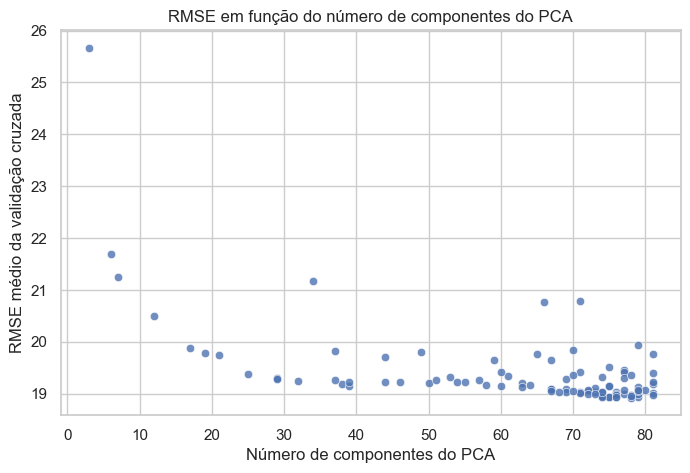

In [34]:
df_estudo = objeto_de_estudo.trials_dataframe()

sns.set_theme(style="whitegrid")

fig, eixo = plt.subplots(figsize=(8, 5))

eixo = sns.scatterplot(
    df_estudo,
    x="params_num_componentes",
    y="value",
    alpha=0.8,
)
eixo.set(
    title="RMSE em função do número de componentes do PCA",
    xlabel="Número de componentes do PCA",
    ylabel="RMSE médio da validação cruzada"
)

*OBS.: Gráfico gerado com auxílio do Claude (Anthropic)*

Observando o gráfico acima do RMSE em função do número de componentes do PCA, é possível notar que usar poucos componentes prejudica bastante o desempenho. O erro cai de forma rápida até aproximadamente $15$ a $20$ componentes e depois se estabiliza, com a maioria das tentativas entre $\sim 19$ e $\sim 20$ para $20$ a $65$ componentes. A partir de cerca de $70$ componentes há uma melhora pequena, até chegar à $78$ (valor com menor RMSE obtido). A concentração de pontos acima de $65$ componentes reflete a busca do `optuna`, que explorou mais a região em que encontrou bons resultados. Os pontos mais dispersos para um mesmo número de componentes mostram que os outros hiperparâmetros também influenciam o resultado, mesmo que menos.

Vamos agora medir o melhor pipeline no conjunto de teste, uma única vez. Observe na célula abaixo:

In [35]:
modelo_knn = cria_instancia_modelo(melhor_trial)
modelo_knn.fit(X_treino, y_treino)

y_verdadeiro = y_teste
y_previsao = modelo_knn.predict(X_teste)

RMSE_KNN_TESTE = root_mean_squared_error(y_verdadeiro, y_previsao)

print(f'RMSE do KNN com PCA no conjunto de teste: {RMSE_KNN_TESTE:.2f} K')
print(f'\nRMSE do baseline no conjunto de teste: {RMSE_BASELINE:.2f} K')
print(f'\nRedução no erro: {(1 - (RMSE_KNN_TESTE/RMSE_BASELINE))*100:.2f}%')

RMSE do KNN com PCA no conjunto de teste: 18.71 K

RMSE do baseline no conjunto de teste: 35.50 K

Redução no erro: 47.31%


Observando acima o desempenho no conjunto de teste, o pipeline otimizado (normalização padrão, PCA com $78$ componentes e KNN com $16$ vizinhos, pesos por distância e distância de Manhattan) treinado com todo o conjunto de treino e avaliado uma única vez no conjunto de teste, obteve RMSE de $18.71\ K$, contra $35.50\ K$ do baseline, uma redução de cerca de $47\%$ no erro. O valor é consistente com o RMSE médio da validação cruzada ($18.92\ K$), o que sugere que a escolha do melhor pipeline entre as $100$ tentativas não resultou em uma estimativa otimista do desempenho. Como a análise foi feita em um único conjunto de teste, essa comparação deve ser vista com cuidado.

Terminada a análise deste pipeline, vamos guardar os resultados de cada modelo em uma tabela que cresce a cada pipeline que formos fazendo:

In [36]:
resultados = pd.DataFrame(
    {
        "Baseline": {"RMSE validação cruzada": RMSE_BASELINE_CV, "RMSE teste": RMSE_BASELINE},
        "KNN + Normalização + PCA": {"RMSE validação cruzada": melhor_trial.value, "RMSE teste": RMSE_KNN_TESTE},
    }
).T

resultados.round(2)

,RMSE validação cruzada,RMSE teste
Baseline,33.96,35.50
KNN + Normalização + PCA,18.92,18.71


##### **Algoritmo 2: Árvore de decisão**

Este algoritmo usa uma árvore de decisão (`DecisionTreeRegressor`) sem normalização nem PCA, pois as divisões da árvore dependem apenas da ordem dos valores de cada atributo, não de sua escala. Os hiperparâmetros otimizados são a profundidade máxima da árvore, o número máximo de vértices folha, o mínimo de exemplos para dividir um nó, o mínimo de exemplos por vértice folha e a fração de atributos por divisão. 

A escolha dos intervalos/valores dos hiperparâmetros mencionados foi feita da seguinte maneira:
* Profundidade máxima (`max_depth`; inteiros de $2$ a $40$): A profundidade controla a complexidade da árvore. Se não limitarmos este hiperparâmetro, o modelo tende a memorizar o treino.
* Número máximo de folhas (`max_leaf_nodes`; inteiros de $10$ a $5000$ (escala log)): Limita diretamente o tamanho da árvore. A escala logarítimica cobre desde árvores pequenas até árvores com milhares de folhas.
* Mínimo de exemplos para que haja split dos dados (`min_samples_split`; inteiros de $2$ a $200$ (escala log)): Evita divisões em nós pequenos. A escala logarítmica cobre valores de poucas unidades a centenas.
* Mínimo de exemplos por vértice folha (`min_samples_leaf`; inteiros de $1$ a $200$ (escala log)): Folhas maiores tornam as previsões mais estáveis.
* Fração de atributos por divisão (`max_features`; de $0.1$ a $1.0$): Sortear atributos em cada divisão reduz o overfitting (modelo com baixo viés e alta variância).

*OBS.: Aplicar a escala log é importante pois diferentemente do padrão do `optuna` que sorteia valores uniformemente, com `log=True` ele sorteia uniformemente nas ordens de grandeza (por exemplo, dando chance parecida a $10$ a $100$ folhas e a $100$ a $1000$ folhas) aumentando a chance de cair valores mais baixos, que ao sortear uniformemente tem menor chance de caírem.*

Abaixo, o algoritmo será implementado a partir de uma adaptação da mesma função já mencionada da referência [9] e criaremos também as funções objetivo e objetivo parcial:

In [37]:
# Função que cria instância do modelo
def cria_modelo_arvore(trial):
    """Cria algoritmo de árvore de decisão para otimização com optuna"""
    
    parametros = {
        # espaço de busca
        "max_depth": trial.suggest_int("profundidade máxima", 2, 40),
        "max_leaf_nodes": trial.suggest_int("max_folhas", 10, 5000, log=True),
        "min_samples_split": trial.suggest_int("min_exemplos_split", 2, 200, log=True),
        "min_samples_leaf": trial.suggest_int("min_exemplos_folha", 1, 200, log=True),
        "max_features": trial.suggest_float("fracao_atributos", 0.1, 1.0),
        # argumentos fixos
        "random_state": SEMENTE_ALEATORIA
    }

    modelo = DecisionTreeRegressor(**parametros)

    return modelo

# Função objetivo do modelo
def funcao_objetivo_arvore(trial, X, y, grupos, num_folds):
    """Função objetivo do optuna

    Referencia:
      https://medium.com/@walter_sperat/ using-optuna-with-sklearn-the-right-way-part-1-6b4ad0ab2451
    """

    modelo = cria_modelo_arvore(trial)

    metricas = cross_val_score(
        modelo,
        X,
        y,
        groups=grupos,
        cv=GroupKFold(n_splits=num_folds),
        scoring="neg_root_mean_squared_error"
    )

    return -metricas.mean()

# Função objetivo parcial
funcao_objetivo_parcial_arvore = partial(
    funcao_objetivo_arvore,
    X=X_treino,
    y=y_treino,
    grupos=grupos_treino,
    num_folds=NUM_FOLDS
)

Com a função que cria a instância do modelo e as funções objetivo feitas, podemos partir para a criação do objeto de estudo:

In [38]:
NOME_DO_ESTUDO_ARVORE = "arvore_decisao_otimizacao"

estudo_arvore = create_study(
    direction="minimize",
    study_name=NOME_DO_ESTUDO_ARVORE,
    storage=f'sqlite:///{NOME_DO_ESTUDO_ARVORE}.db',
    load_if_exists=True,
    sampler=TPESampler(seed=SEMENTE_ALEATORIA)
)

trials_feitos_arvore = len(estudo_arvore.get_trials(states=(TrialState.COMPLETE,))) # Medida de segurança caso o 
# notebook entre em suspensão e para permitir que o notebook rode novamente do zero sem criar novas tentativas

Agora, com o objeto de estudo criado e o algoritmo implementado na função `funcao_objetivo_parcial_arvore`, a otimização será rodada na célula abaixo:

In [39]:
estudo_arvore.optimize(
    funcao_objetivo_parcial_arvore, 
    n_trials=NUM_TENTATIVAS - trials_feitos_arvore, 
    n_jobs=10
)

A execução original da célula acima demorou apenas $56.6$ segundos. Vamos agora checar qual foi o melhor resultado encontrado pela otimização do `optuna`:

In [40]:
melhor_trial_arvore = estudo_arvore.best_trial

print(f"Número de tentativas no estudo: {len(estudo_arvore.trials)}")
print(f"Número do melhor trial: {melhor_trial_arvore.number}")
print(f"Parâmetros do melhor trial: {melhor_trial_arvore.params}")
print(f"RMSE médio (validação cruzada) do melhor trial: {melhor_trial_arvore.value:.2f} K")

Número de tentativas no estudo: 100
Número do melhor trial: 29
Parâmetros do melhor trial: {'profundidade máxima': 31, 'max_folhas': 41, 'min_exemplos_split': 2, 'min_exemplos_folha': 75, 'fracao_atributos': 0.6324946709264092}
RMSE médio (validação cruzada) do melhor trial: 18.42 K


Analisando os resultados acima, percebe-se que a melhor combinação (tentativa $29$) usou limite de $41$ vértices folha, mínimo de $75$ exemplos por vértice folha, profundidade máxima de $31$, fração de $0.63$ dos atributos por divisão e mínimo de $2$ exemplos para dividir um nó, com RMSE médio de validação cruzada de $18.42\ K$, contra $33.96\ K$ do baseline na mesma validação, o que representa uma redução de aproximadamente $46\%$ no erro.

Nesta combinação de hiperparâmetros obtida, o tamanho da árvore é controlado pelo limite de folhas, onde com apenas $41$ folhas, o limite de profundidade provavelmente não atua, e como cada folha exige ao menos $75$ exemplos, o mínimo de $2$ para fazer o split dos dados também não. Ou seja, a árvore gerada por essa combinação é uma árvore pequena e regularizada (tende a generalizar melhor dados novos). 

Vamos analisar graficamente os resultados:

In [41]:
vis.plot_optimization_history(estudo_arvore)

O gráfico do histórico acima mostra que o melhor RMSE médio de validação cruzada caiu em degraus nas primeiras tentativas, de cerca de $19.6\ K$ para aproximadamente $18.85\ K$, $18.62\ K$ (na tentativa $11$) e $18.42\ K$ (tentativa $29$), sem melhora nas tentativas seguintes. 

In [42]:
vis.plot_param_importances(estudo_arvore)

Analisando o gráfico de importância dos hiperparâmetros acima nota-se que a profundidade máxima da árvore foi, de longe, o hiperparâmetro de maior importância ($0.68$), seguida da fração de atributos por divisão ($0.22$), enquanto o mínimo de exemplos por vértice folha ($0.06$), o mínimo para o split dos dados ($0.03$) e o número máximo de vértices folha ($< 0.01$) tiveram pouca importância. Essa importância mede quanto da variação do RMSE entre as tentativas está associada a cada hiperparâmetro, e não qual restrição atua melhor na combinação, onde na melhor árvore obtida, por exemplo, o tamanho é limitado pelo número de vértices folha ($41$), apesar de este ser o hiperparâmetro de menor importância. 

Como o hiperparâmetro mais importante foi a profundidade máxima da árvore, vamos analisar um gráfico de dispersão da profundidade contra o RMSE:

[Text(0.5, 1.0, 'RMSE em função da profundidade máxima da árvore'),
 Text(0.5, 0, 'Profundidade máxima'),
 Text(0, 0.5, 'RMSE médio da validação cruzada')]

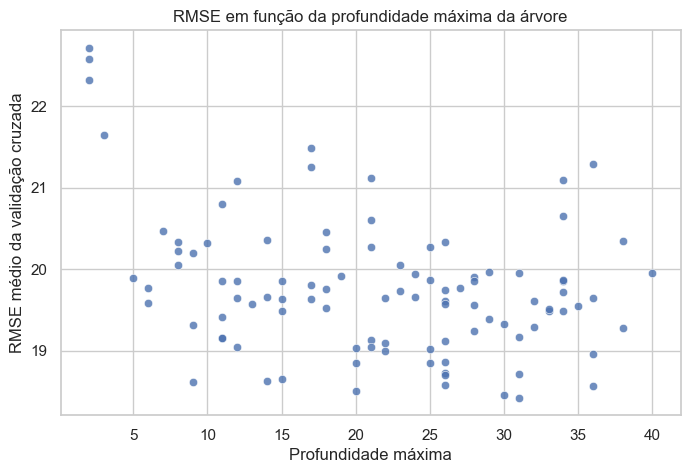

In [43]:
df_arvore = estudo_arvore.trials_dataframe()

fig, eixo = plt.subplots(figsize=(8, 5))

eixo = sns.scatterplot(
    df_arvore,
    x="params_profundidade máxima",
    y="value",
    alpha=0.8,
)
eixo.set(
    title="RMSE em função da profundidade máxima da árvore",
    xlabel="Profundidade máxima",
    ylabel="RMSE médio da validação cruzada"
)

Observando o gráfico de dispersão da profundidade máxima acima é possível notar que árvores muito rasas têm os piores desempenhos, com RMSE acima de $21.5\ K$, mas, com profundidade a partir de aproximadamente $5$ a $10$, não é possível perceber uma tendência clara, visto que, para qualquer profundidade, o RMSE varia entre cerca de $18.5\ K$ a $21.5\ K$, e os melhores valores aparecem em profundidades bem distintas. Assim, a alta importância da profundidade ($0.70$) reflete principalmente a penalização das árvores muito rasas. Acima de certo valor, a profundidade deixa de ser a restrição ativa, e a variação do RMSE passa a depender principalmente dos demais hiperparâmetros.

Para verificar se o limite de profundidade obtido no melhor modelo ($31$) realmente não atua devido ao limite de $41$ vértices folha, vamos, a partir de um treino do melhor modelo apenas com o conjunto de treino, observar o que a melhor árvore realmente tem

In [44]:
modelo_arvore = cria_modelo_arvore(melhor_trial_arvore)
modelo_arvore.fit(X_treino, y_treino)

print(f"Profundidade real da árvore: {modelo_arvore.get_depth()}")
print(f"Número real de vértices folhas: {modelo_arvore.get_n_leaves()}")

Profundidade real da árvore: 9
Número real de vértices folhas: 41


Ou seja, o limite de folhas foi atingido, enquanto o limite de profundidade não foi, o que é consistente com o gráfico anterior.

Como já o melhor modelo já foi treinado com o treino na célula de código acima, vamos medir o algoritmo no conjunto de teste, uma única vez:

In [45]:
y_verdadeiro = y_teste
y_previsao = modelo_arvore.predict(X_teste)

RMSE_ARVORE_TESTE = root_mean_squared_error(y_verdadeiro, y_previsao)

print(f'RMSE da árvore de decisão no teste: {RMSE_ARVORE_TESTE:.2f} K')
print(f'\nRMSE do baseline no conjunto de teste: {RMSE_BASELINE:.2f} K')
print(f'\nRedução no erro: {(1 - (RMSE_ARVORE_TESTE/RMSE_BASELINE))*100:.2f}%')

RMSE da árvore de decisão no teste: 18.94 K

RMSE do baseline no conjunto de teste: 35.50 K

Redução no erro: 46.66%


Observando acima o desempenho no conjunto de teste, o algoritmo de árvore de decisão otimizado (limite de $41$ vértices folhas, mínimo de $75$ exemplos por vértice folha, profundidade máxima de $31$ e fração de $0.63$ dos atributos por divisão) treinado com todo o conjunto de treino e avaliado uma única vez no conjunto de teste, obteve RMSE de $18.94\ K$, contra $35.50\ K$ do baseline, uma redução de cerca de $46.7\%$ no erro. Esse valor é cerca de $0.5\ K$ maior que o RMSE médio da validação cruzada ($18.42\ K$), o que é compatível com o efeito de realizar a escolha da melhor combinação entre as $100$ tentativas.

Se compararmos com o pipeline 1 (KNN com PCA), a árvore teve RMSE menor na validação cruzada ($18.42\ K$ contra $18.92\ K$; diferença de $0.5\ K$) e maior no teste ($18.94\ K$ contra $18.71\ K$; diferença de $-0.23\ K$). As diferenças, de poucos décimos de kelvin, podem indicar que o pipeline 1 e o algoritmo 2 apresentam desempenhos similares.

Terminada a análise deste algoritmo, vamos guardar os resultados do modelo na tabela criada anteriormente:

In [46]:
resultados.loc["Árvore de decisão"] = [melhor_trial_arvore.value, RMSE_ARVORE_TESTE]
resultados.round(2)

,RMSE validação cruzada,RMSE teste
Baseline,33.96,35.50
KNN + Normalização + PCA,18.92,18.71
Árvore de decisão,18.42,18.94


##### **Algoritmo 3: Floresta Aleatória**

Este algoritmo utiliza uma floresta aleatória (`RandomForestRegressor`), que treina muitas árvores em amostras diferentes dos dados, sorteando também os atributos considerados em cada split, e faz a média das previsões. Isso reduz a variância de uma árvore isolada, que, como visto no algoritmo 2, é sensível aos hiperparâmetros. Assim como a árvore, a floresta de decisão não necessita de normalização nem PCA. Os hiperparâmetros otimizados são o número de árvores, a profundidade máxima por árvore, o mínimo de exemplos para fazer split dos dados, o mínimo de exemplos por vértice folha, a fração de atributos por split e a fração de amostras por árvore.

A escolha dos intervalos/valores dos hiperparâmetros mencionados foi feita da seguinte maneira:
* Número de árvores (`n_estimators`; inteiros de $50$ a $200$ (escala log)): Mais árvores estabilizam a média, com ganhos decrescentes e custo crescente.
* Profundidade máxima (`max_depth`; inteiros de $5$ a $40$): Limita a complexidade de cada árvore. Valores muito pequenos tendem a prejudicar o desempenho, como observado no algoritmo 2.
* Mínimo de exemplos para split dos dados (`min_samples_split`; inteiros de $2$ a $100$ (escala log)): Evita divisões em nós pequenos.
* Mínimo de exemplos por vértice folha (`min_samples_leaf`; inteiros de $1$ a $50$ (escala log)): Folhas maiores tornam as previsões mais estáveis.
* Fração de atributos por divisão (`max_features`; de $0.1$ a $0.6$): Sortear atributos descorrelaciona árvores. Diferente do algoritmo 2, pelo fato da floresta aleatória ser mais custosa, este hiperparâmetro foi limitado a $0.6$ pois o tempo de treino cresce com a fração.
* Fração de amostras por árvore (`max_samples`; de $0.2$ a $0.8$): Cada árvore é treinada com uma amostra com reposição desse tamanho, o que evita o overfitting e reduz o tempo de treino.

Além disso, foi fixado o uso de amostragem com reposição (`bootstrap=True`, necessário para a fração de amostras).

Na célula abaixo, criaremos a função que implementa o algoritmo e as funções objetivo:

In [47]:
# Criando função que implementa o algoritmo
def cria_modelo_floresta(trial):
    """Cria algoritmo de floresta aleatória com otimização por optuna"""

    parametros = {
        # espaço de busca
        "n_estimators": trial.suggest_int("num_arvores", 50, 200, log=True),
        "max_depth": trial.suggest_int("profundidade_maxima", 5, 40),
        "min_samples_split": trial.suggest_int("min_exemplos_split", 2, 100, log=True),
        "min_samples_leaf": trial.suggest_int("min_exemplos_folha", 1, 50, log=True),
        "max_features": trial.suggest_float("fracao_atributos", 0.1, 0.6),
        "max_samples": trial.suggest_float("fracao_amostras", 0.2, 0.8),
        # argumentos fixos
        "bootstrap": True,
        "n_jobs": 10,
        "random_state": SEMENTE_ALEATORIA
    }

    modelo = RandomForestRegressor(**parametros)

    return modelo

# Função objetivo do modelo
def funcao_objetivo_floresta(trial, X, y, grupos, num_folds):
    """Função objetivo do optuna

    Referencia:
      https://medium.com/@walter_sperat/ using-optuna-with-sklearn-the-right-way-part-1-6b4ad0ab2451
    """

    modelo = cria_modelo_floresta(trial)

    metricas = cross_val_score(
        modelo,
        X,
        y,
        groups=grupos,
        cv=GroupKFold(n_splits=num_folds),
        scoring="neg_root_mean_squared_error"
    )

    return -metricas.mean()

# Função objetivo parcial
funcao_objetivo_parcial_floresta = partial(
    funcao_objetivo_floresta,
    X=X_treino,
    y=y_treino,
    grupos=grupos_treino,
    num_folds=NUM_FOLDS
)

Com a função que cria a instância do modelo e as funções objetivo feitas, podemos partir para a criação do objeto de estudo:

In [48]:
NOME_DO_ESTUDO_FLORESTA = "floresta_aleatoria_otimizacao"

estudo_floresta = create_study(
    direction="minimize",
    study_name=NOME_DO_ESTUDO_FLORESTA,
    storage=f"sqlite:///{NOME_DO_ESTUDO_FLORESTA}.db",
    load_if_exists=True,
    sampler=TPESampler(seed=SEMENTE_ALEATORIA),
)

trials_feitos_floresta = len(estudo_floresta.get_trials(states=(TrialState.COMPLETE,))) # Medida de segurança caso o 
# notebook entre em suspensão e para permitir que o notebook rode novamente do zero sem criar novas tentativas

Agora, com o objeto de estudo criado e o algoritmo implementado na função `funcao_objetivo_parcial_floresta`, a otimização será rodada na célula abaixo:

In [49]:
NUM_TENTATIVAS = 100

estudo_floresta.optimize(
    funcao_objetivo_parcial_floresta,
    n_trials=NUM_TENTATIVAS - trials_feitos_floresta
)

A execução original da célula acima demorou $49$ minutos e $43.1$ segundos. Vamos agora checar qual foi o melhor resultado encontrado pela otimização do `optuna`:

In [50]:
melhor_trial_floresta = estudo_floresta.best_trial

print(f"Número de tentativas no estudo: {len(estudo_floresta.trials)}")
print(f"Número do melhor trial: {melhor_trial_floresta.number}")
print(f"Parâmetros do melhor trial: {melhor_trial_floresta.params}")
print(f"\nRMSE médio (validação cruzada) do melhor trial: {melhor_trial_floresta.value:.2f} K")

Número de tentativas no estudo: 100
Número do melhor trial: 91
Parâmetros do melhor trial: {'num_arvores': 172, 'profundidade_maxima': 39, 'min_exemplos_split': 4, 'min_exemplos_folha': 2, 'fracao_atributos': 0.4611558090771662, 'fracao_amostras': 0.7345545003418905}

RMSE médio (validação cruzada) do melhor trial: 15.03 K


Analisando os resultados acima, percebe-se que a melhor combinação (tentativa $91$) usou $172$ árvores, profundidade máxima de $39$, mínimo de $4$ exemplos para fazer split dos dados e de $2$ exemplos por vértice folha, fração de $0.46$ dos atributos por divisão e de $0.73$ das amostras por árvore, com RMSE médio de validação cruzada de $15.03\ K$, contra $33.96\ K$ do baseline na mesma validação, o que representa uma redução de aproximadamente $56\%$ no erro.

Diferentemente da árvore isolada (algoritmo 2), que preferiu uma árvore pequena e fortemente regularizada (com forte redução do overfitting), a floresta selecionou árvores profundas, com folhas pequenas, o que é coerente com o funcionamento do modelo, onde a média de muitas árvores reduz a variância de cada uma. Note que alguns dos valores selecionados ficaram próximos dos limites do espaço de busca (profundidade $39$ de no máximo $40$, fração de amostras $0.73$ de no máximo $0.8$ e $172$ árvores de no máximo $200$), que foram restringidos a fim de evitar um longo tempo de execução, de modo que valores maiores poderiam melhorar levemente o resultado (isso é uma hipótese!).

Agora, vamos analisar graficamente os resultados:

In [51]:
vis.plot_optimization_history(estudo_floresta)

O gráfico do histórico acima mostra que o melhor RMSE médio de validação cruzada caiu de forma rápida nas primeiras tentativas (de cerca de $16\ K$ para $15.3\ K$ na tentativa $4$ e $15.1\ K$ na tentativa $24$), permaneceu praticamente linear até a tentativa $84$ e teve pequenos ganhos finais, menores que um décimo de $K$. Diferentemente do algoritmo 2 que mostrou uma dispersão significativa entre as últimas tentativas, o algoritmo da floresta apresentou um dispersão bem menor. 

In [52]:
vis.plot_param_importances(estudo_floresta)

Observando o gráfico de importância dos hiperparâmetros representado acima, é possível perceber que a profundidade máxima ($0.40$) e o mínimo de exemplos por vértice folha ($0.30$), os dois hiperparâmetros que controlam a complexidade da árvore, foram os considerados mais importantes pelo `optuna`, seguidos da fração de amostras por árvore ($0.19$). O mínimo de exemplos para dividir ($0.08$), o número de árvores ($0.01$) e a fração dos atributos ($0.01$) tiveram pouca importância, o que faz sentido já que com algumas dezenas de árvores a média da floresta já fica estabilizada.

Considerando os três hiperparâmetros considerados mais importantes, vamos analisar um gráfico de dispersão para a profundidade máxima, mínimo de exemplos por folha e fração de amostras por árvore, contra o RMSE. Observe abaixo três gráficos de dispersão, um para cada um dos três hiperparâmetros mais importantes, gerados com auxílio do Claude (Anthropic):

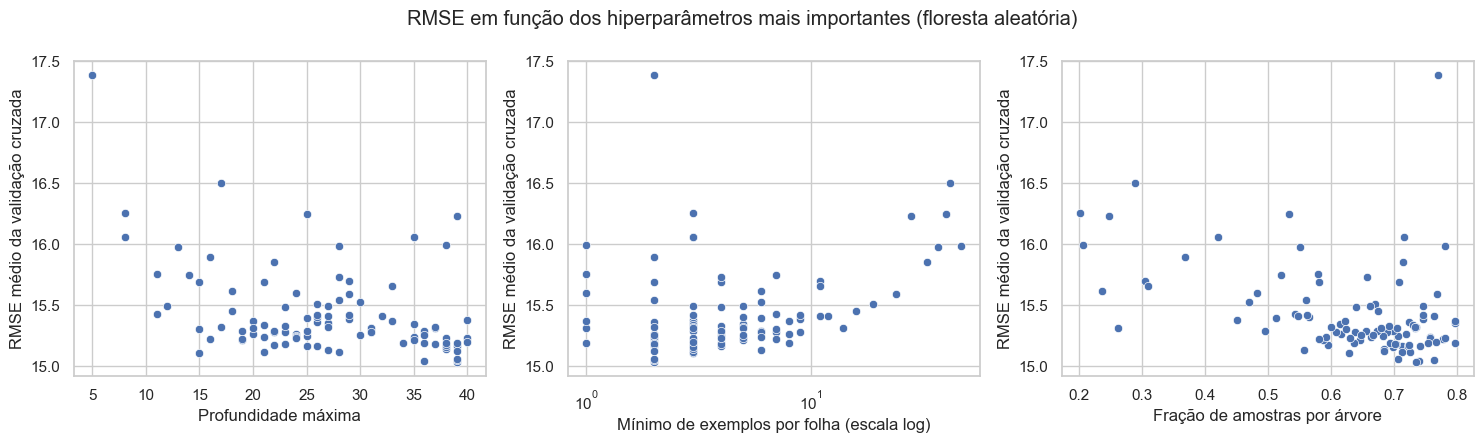

In [53]:
df_floresta = estudo_floresta.trials_dataframe()

fig, eixos = plt.subplots(1, 3, figsize=(15, 4.5))

sns.scatterplot(data=df_floresta, x="params_profundidade_maxima", y="value", ax=eixos[0])
eixos[0].set(xlabel="Profundidade máxima", ylabel="RMSE médio da validação cruzada")

sns.scatterplot(data=df_floresta, x="params_min_exemplos_folha", y="value", ax=eixos[1])
eixos[1].set(xscale="log", xlabel="Mínimo de exemplos por folha (escala log)", ylabel="RMSE médio da validação cruzada")

sns.scatterplot(data=df_floresta, x="params_fracao_amostras", y="value", ax=eixos[2])
eixos[2].set(xlabel="Fração de amostras por árvore", ylabel="RMSE médio da validação cruzada")

fig.suptitle("RMSE em função dos hiperparâmetros mais importantes (floresta aleatória)")
plt.tight_layout()
plt.show()

Observando os gráficos de disperão acima, nota-se que, no primeiro gráfico da profundidade máxima, o hiperparâmetro prejudica o resultado quando a profundidade é pequena (RMSE entre cerca de $16\ K$ e $17.4\ K$ com profundidades de $5$ a $\sim 8$) e o RMSE cai até profundidade de cerca de $15$ a $20$, com uma melhora gradual depois. 

No segundo gráfico, para o mínimo de exemplos por vértice folha, cujo eixo x do gráfico está em escala logarítmica, a maior parte dos pontos de menor RMSE (em torno de $15.0\ K$ a $15.3\ K$) fica à esquerda da marca de $10^1$, ou seja, para valores abaixo de $10$ exemplos por folha. Para valores maiores que $10$ o RMSE tende a aumentar, e os piores resultados ocorrem para os maiores valores do eixo. Isso indica que folhas muito grandes prejudicam o desempenho, enquanto folhas pequenas são melhores.

No terceiro gráfico, da fração de amostras por árvore, valores abaixo de cerca de $0.4$ resultaram em um RMSE mais alto e disperso (de aproximadamente $15.3\ K$ a $16.5\ K$), e a partir de cerca de $0.6$ a $0.7$ os resultados se concentram em torno de $15.1\ K $ a $15.5\ K$, sem uma melhora visível entre $0.75$ a $0.8$, de modo que o limite superior de $0.8$ provavelmente não restringiu a busca.

Agora, vamos medir o melhor modelo obtido no conjunto de teste, uma única vez:

In [54]:
modelo_floresta = cria_modelo_floresta(melhor_trial_floresta)
modelo_floresta.fit(X_treino, y_treino)

y_verdadeiro = y_teste
y_previsao = modelo_floresta.predict(X_teste)

RMSE_FLORESTA_TESTE = root_mean_squared_error(y_verdadeiro, y_previsao)

print(f'RMSE da floresta aleatória no conjunto de teste: {RMSE_FLORESTA_TESTE:.2f} K')
print(f'\nRMSE do baseline no conjunto de teste: {RMSE_BASELINE:.2f} K')
print(f'\nRedução no erro: {(1 - (RMSE_FLORESTA_TESTE/RMSE_BASELINE))*100:.2f}%')

RMSE da floresta aleatória no conjunto de teste: 14.45 K

RMSE do baseline no conjunto de teste: 35.50 K

Redução no erro: 59.30%


Analisando acima o desempenho no conjunto de teste, o algoritmo de floresta aleatória otimizado ($172$ árvores, profundidade máxima de $39$, mínimo de $4$ exemplos para split dos dados e de $2$ por vértice folha, fração de $0.46$ dos atributos por split e de $0.73$ das amostras por árvore) treinado com todo o conjunto de treino e avaliado uma única vez no conjunto de teste, obteve RMSE de $14.45\ K$, contra $35.50\ K$ do baseline, uma redução de aproximadamente $59.3\%$ no erro. O valor é um pouco menor que o RMSE médio da validação cruzada ($15.03\ K$), com uma diferença de cerca de $0.6\ K$, inferior à variação entre folds.

A floresta teve o menor RMSE tanto na validação cruzada quanto no teste (pipeline 1: $18.92\ K$ e $18.71\ K$; algoritmo 2: $18.42\ K$ e $18.94\ K$), com margem de aproximadamente $3.4\ K$ a $4.5\ K$, muito superior à variação entre folds, de modo que o algoritmo da floresta aleatória é superior nos dois métodos de avaliação em relação aos outros modelos até agora testados.

Por fim, na célula abaixo, o modelo será guardado na tabela feita:

In [55]:
resultados.loc["Floresta aleatória"] = [melhor_trial_floresta.value, RMSE_FLORESTA_TESTE]
resultados.round(2)

,RMSE validação cruzada,RMSE teste
Baseline,33.96,35.50
KNN + Normalização + PCA,18.92,18.71
Árvore de decisão,18.42,18.94
Floresta aleatória,15.03,14.45


##### **Pipeline 4: Regressão linear com normalização, PCA e termos polinomiais**

Este pipeline combina quatro etapas, sendo elas a normalização dos atributos, redução de dimensionalidade com PCA, atributos polinomiais e regressão linear (`LinearRegression`).

Segundo a referência [2], um polinômio é um modelo linear nos parâmetros e, por isso, pode ser ajustado por uma regressão linear múltipla sobre atributos polinomiais. Isso permite que o pipeline represente relações não lineares entre os atributos e o alvo, como as observadas na análise exploratória. O PCA é adequado aqui porque a regressão linear é sensível à forte multicolinearidade dos atributos (VIF acima de 10 em todos eles) e, por produzir componentes não correlacionados, também limita o número de atributos polinomiais gerados. O fato da regressão linear por si só não possuir hiperparâmetros relevantes faz com que o espaço de busca restrinja-se ao pré-processamento e ao grau do polinômio. Portanto, os hiperparâmetros otimizados são o tipo de normalização, o número de componentes do PCA e o grau do polinômio.

A escolha dos intervalos/valores dos hiperparâmetros acima foi feita da seguinte maneira:
* Normalização (`StandardScaler` ou `MinMaxScaler`): O PCA depende das variâncias dos atributos, e a análise exploratória mostrou escalas muito diferentes, então a normalização é sempre aplicada.
* Número de componentes do PCA (inteiros de $1$ a $40$): Limitado a $40$ pois, com grau 2, o número de atributos gerados cresce rapidamente, o que torna a regressão sem regularização (sem aplicar pesos nos coeficientes) lenta e propensa a overfitting [Claude].
* Grau do polinômio ($1$ ou $2$): O grau $1$ é a regressão linear simples e o $2$ acrescenta quadrados e produtos entre as componentes. Graus maiores geram atributos demais para uma regressão sem regularização.

Como o espaço de busca é pequeno ($2 \times 40 \times 2 = 160$ combinações) e devem ser feitos pelo menos $100$ conjuntos diferentes de hiperparâmetros, será usado o amostrador de grade do optuna (`GridSampler`), que avalia cada combinação exatamente uma vez, evitando as repetições que o amostrador padrão (`TPE`) poderia gerar.

Na célula abaixo, criaremos a função que implementa o algoritmo e as funções objetivo:

In [56]:
NUM_MAX_COMPONENTES = 40

# Criando função que implementa o algoritmo
def cria_modelo_linear_pca(trial):
    """Cria pipeline de regressão linear com normalização, PCA e termos polinomiais"""

    tipo_normalizacao = trial.suggest_categorical("normalizacao", ["padrao", "minmax"])

    if tipo_normalizacao == "padrao":
        normalizador = StandardScaler()
    else:
        normalizador = MinMaxScaler()

    num_componentes = trial.suggest_int("num_componentes", 1, NUM_MAX_COMPONENTES)
    grau_polinomio = trial.suggest_categorical("grau_polinomio", [1, 2])

    modelo = make_pipeline(
        normalizador,
        PCA(num_componentes, random_state=SEMENTE_ALEATORIA),
        PolynomialFeatures(grau_polinomio, include_bias=False),
        LinearRegression()
    )

    return modelo

# Função objetivo do modelo
def funcao_objetivo_linear_pca(trial, X, y, grupos, num_folds):
    """Função objetivo do optuna

    Referencia:
      https://medium.com/@walter_sperat/ using-optuna-with-sklearn-the-right-way-part-1-6b4ad0ab2451
    """

    modelo = cria_modelo_linear_pca(trial)

    metricas = cross_val_score(
        modelo,
        X,
        y,
        groups=grupos,
        cv=GroupKFold(n_splits=num_folds),
        scoring="neg_root_mean_squared_error"
    )

    return -metricas.mean()

# Função objetivo parcial
funcao_objetivo_parcial_linear_pca = partial(
    funcao_objetivo_linear_pca,
    X=X_treino,
    y=y_treino,
    grupos=grupos_treino,
    num_folds=NUM_FOLDS
)

Com a função que cria a instância do modelo e as funções objetivo feitas, podemos partir para a criação do objeto de estudo:

In [57]:
NOME_DO_ESTUDO_LINEAR_PCA = "linear_pca_poli_v2"

espaço_de_busca = {
    "normalizacao": ["padrao", "minmax"],
    "num_componentes": list(range(1, NUM_MAX_COMPONENTES + 1)),
    "grau_polinomio": [1, 2]
}

NUM_COMBINACOES = 2 * NUM_MAX_COMPONENTES * 2

estudo_linear_pca = create_study(
    direction="minimize",
    study_name=NOME_DO_ESTUDO_LINEAR_PCA,
    storage=f'sqlite:///{NOME_DO_ESTUDO_LINEAR_PCA}.db',
    load_if_exists=True,
    sampler=GridSampler(espaço_de_busca, seed=SEMENTE_ALEATORIA)
)

trials_feitos_linear_pca = len(estudo_linear_pca.get_trials(states=(TrialState.COMPLETE,)))# Medida de segurança caso o 
# notebook entre em suspensão e para permitir que o notebook rode novamente do zero sem criar novas tentativas

Agora, com o objeto de estudo criado e o algoritmo implementado na função `funcao_objetivo_parcial_linear_pca`, a otimização será rodada na célula abaixo:

In [58]:
if len(estudo_linear_pca.trials) < NUM_COMBINACOES:
    estudo_linear_pca.optimize(
        funcao_objetivo_parcial_linear_pca,
        n_trials=NUM_COMBINACOES - trials_feitos_linear_pca
    )

A execução original da célula acima demorou $4$ minutos. Vamos agora checar qual foi o melhor resultado encontrado pela otimização do `optuna`:

In [59]:
melhor_trial_linear_pca = estudo_linear_pca.best_trial

print(f"Número de tentativas no estudo: {len(estudo_linear_pca.trials)}")
print(f"Número do melhor trial: {melhor_trial_linear_pca.number}")
print(f"Parâmetros do melhor trial: {melhor_trial_linear_pca.params}")
print(f"\nRMSE médio (validação cruzada) do melhor trial: {melhor_trial_linear_pca.value:.2f} K")

Número de tentativas no estudo: 160
Número do melhor trial: 62
Parâmetros do melhor trial: {'normalizacao': 'padrao', 'num_componentes': 23, 'grau_polinomio': 2}

RMSE médio (validação cruzada) do melhor trial: 18.43 K


Observando os resultados acima, percebe-se que a melhor combinação do pipeline 4, com amostrador de grade, usou normalização padrão, PCA com $23$ componentes e polinômio de grau $2$, com RMSE médio de validação cruzada de $18.43\ K$, contra $33.96\ K$ do baseline na mesma validação, o que representa uma redução de cerca de $45.7\%$ no erro.

O fato do grau $2$ superar o grau $1$ é consistente com o fato observado na análise exploratória dos atributos não apresentarem uma relação linear com o alvo, e o número de componentes selecionados ($23$) ficou bem abaixo do limite superior escolhido ($40$), então o intervalo não restringiu a busca. O desempenho do pipeline 4 foi semelhante ao do algoritmo da árvore de decisão, que apresentou RMSE médio de validação cruzada de $18.42\ K$, e um pouco melhor que o pipeline de KNN com normalização e PCA, que apresentou $18.92\ K$. No entanto, ficou cerca de $3.4\ K$ acima do algoritmo de floresta aleatória ($15.03\ K$).

Como o amostrador de grade usado (`GridSampler`) testa todas as combinações em ordem aleatória, garantindo uma busca exaustiva sem repetições, a linha do gráfico de histórico do `optuna` que fizemos para os outros algortimos só irá mostrar a ordem do sorteio, e não uma convergência da busca como ocorreu nos pipelines com o `TPESampler`. O resultado final obtido com a amostragem em grade independe da ordem de avaliação, portanto não há motivo de analisarmos esse gráfico.

Com isso, vamos analisar os resultados graficamente:

In [60]:
vis.plot_param_importances(estudo_linear_pca)

Analisando o gráfico de importância dos hiperparâmetros representado acima, nota-se que o número de componentes do PCA ($0.66$) e o grau do polinômio ($0.34$) respondem a praticamente toda a variação do RMSE entre as combinações testadas pelo `optuna`, enquanto o tipo de normalização teve importância desprezível ($< 0.01$), ou seja, `StandardScaler` e `MinMaxScaler` tiveram resultados muito próximos. A alta importância do grau do polinômio, que assume só $2$ valores, mostra que colocar os termos quadráticos altera bem o desempenho do modelo. Essas importâncias são relativas ao intervalo escolhido e testado. O intervalo de componentes (de $1$ a $40$) por exemplo, inclui valores pequenos, com RMSE alto, que contribuem bastante para a importância dada a esse hiperparâmetro.

Na célula abaixo, será feito um gráfico (gerado com auxílio do Claude) do RMSE em função do número de componentes, separado por grau, para verificarmos como se dá a variação da métrica:

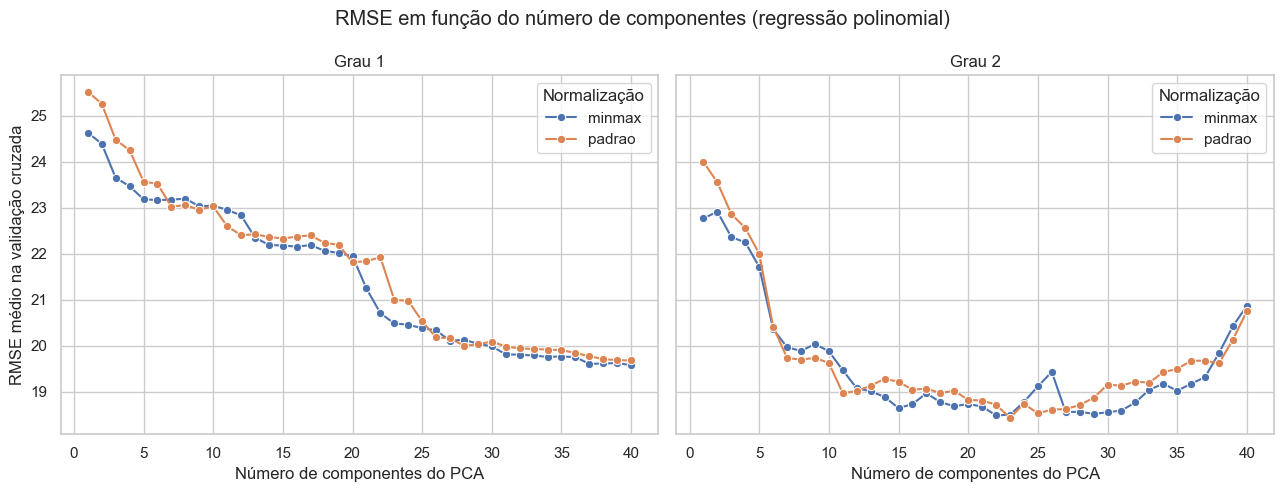

In [61]:
df_linear = estudo_linear_pca.trials_dataframe()

fig, eixos = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

for ax, grau in zip(eixos, [1, 2]):
    dados = df_linear[df_linear["params_grau_polinomio"] == grau]
    sns.lineplot(
        data=dados,
        x="params_num_componentes",
        y="value",
        hue="params_normalizacao",
        marker="o",
        ax=ax,
    )
    ax.set_title(f"Grau {grau}")
    ax.set_xlabel("Número de componentes do PCA")
    ax.set_ylabel("RMSE médio na validação cruzada")
    ax.legend(title="Normalização")

fig.suptitle("RMSE em função do número de componentes (regressão polinomial)")
plt.tight_layout()
plt.show()

Observando o gráfico do RMSE em função do número de componentes, separado por grau, é possível perceber que no gráfico de grau $1$, o RMSE diminui quase continuamente com o número de componentes (de cerca de $25\ K$ com um componente para cerca de $19.6\ K$ com $40$) e ainda decrescia no limite do intervalo, de modo que a restrição a $40$ componentes pode ter limitado esse caso. No grau $2$, o RMSE cai rapidamente até cerca de $10$ componentes, atinge o mínimo em $23$ componentes e volta subir para valores maiores, comportamento típico de overfitting, já que a expansão polinomial gera centenas de atributos e a regressão não é regularizada. Para um mesmo número de componentes, o grau $2$ é bem melhor que o grau $1$ na maior parte do intervalo, mas passa a ser pior para valores próximos de $40$. As duas normalizações produzem curvas muito próximas, o que explicíta a baixa importância desse hiperparâmetro.

Agora vamos medir o melhor modelo obtido no conjunto de teste, uma única vez:

In [62]:
modelo_linear_pca = cria_modelo_linear_pca(melhor_trial_linear_pca)
modelo_linear_pca.fit(X_treino, y_treino)

y_verdadeiro = y_teste
y_previsao = modelo_linear_pca.predict(X_teste)

RMSE_LINEAR_PCA_TESTE = root_mean_squared_error(y_verdadeiro, y_previsao)

print(f'RMSE da regressão linear polinomial no conjunto de teste: {RMSE_LINEAR_PCA_TESTE:.2f} K')
print(f'\nRMSE do baseline no conjunto de teste: {RMSE_BASELINE:.2f} K')
print(f'\nRedução no erro: {(1 - (RMSE_LINEAR_PCA_TESTE/RMSE_BASELINE))*100:.2f}%')

RMSE da regressão linear polinomial no conjunto de teste: 17.23 K

RMSE do baseline no conjunto de teste: 35.50 K

Redução no erro: 51.46%


Analisando o desempenho no conjunto de teste, o pipeline de regressão linear polinomial otimizado (normalização padrão, PCA com $23$ componentes e polinômio de grau $2$) treinado com todo o conjunto de treino e avaliado uma única vez no conjunto de teste, obteve RMSE de $17.23\ K$, contra $35.50\ K$ do baseline, uma redução de aproximadamente $51.5\%$ no erro. O valor é cerca de $1.2\ K$ menor que o RMSE médio da validação cruzada ($18.43\ K$), diferença próxima do limite da variação entre folds.

Na validação cruzada, esse pipeline teve desempenho similar ao algoritmo da árvore de decisão ($18.43\ K$ e $18.42\ K$) e um pouco melhor que o pipeline do KNN ($18.92\ K$), mas no teste, ficou com RMSE abaixo de ambos. Tanto na validação cruzada como na avaliação no conjunto de teste, o algoritmo da floresta aleatória foi superior.

Por fim, na célula abaixo, o modelo será guardado na tabela feita:

In [63]:
resultados.loc["Regressão linear + PCA + polinômio"] = [melhor_trial_linear_pca.value, RMSE_LINEAR_PCA_TESTE]
resultados.round(2)

,RMSE validação cruzada,RMSE teste
Baseline,33.96,35.50
KNN + Normalização + PCA,18.92,18.71
Árvore de decisão,18.42,18.94
Floresta aleatória,15.03,14.45
Regressão linear + PCA + polinômio,18.43,17.23


##### **Pipeline 5: Regressão linear com normalização, RFE e termos polinomiais**

Este pipeline combina quatro etapas, assim como o anterior porém substituindo a redução de dimensionalidade do pipeline 4 por seleção de atributos.

A remoção recursiva de atributos (RFE) com regressão linear mantém apenas um número definido dos atributos originais, descartando a cada passo o de menor peso no modelo [4]. Diferentemente do PCA, preserva atributos interpretáveis, o que permite comparar as duas estratégias para lidar com a multicolinearidade. Em seguida, o pipeline aplica a expansão polinomial e a regressão linear. Como o RFE ordena os atributos pelo tamanho de seus coeficientes, que dependem da escala, a normalização é essencial.

A escolha dos intervalos/valores dos hiperparâmetros acima foi feita da seguinte maneira:
* Normalização (`StandardScaler` ou `MinMaxScaler`): O RFE compara coeficientes, que só são comparáveis se os atriutos estiverem na mesma escala.
* Número de atributos selecionados (inteiros de $1$ a $40$): Limitado a $40$ pois, com grau 2, o número de atributos gerados cresce rapidamente, o que torna a regressão sem regularização (sem aplicar pesos nos coeficientes) lenta e propensa a overfitting.
* Grau do polinômio ($1$ ou $2$): O grau $1$ é a regressão linear simples e o $2$ acrescenta quadrados e produtos entre as componentes. Graus maiores geram atributos demais para uma regressão sem regularização.

Será utilizado o RFE com `step=2`, que remove 2 atributos por iteração , em vez de 1 (padrão), o que reduz o tempo de execução quase pela metade em relação ao padrão. Pelo mesmo motivo do pipeline anterior, será usado o amostrador de grade do optuna (`GridSampler`), que avalia cada combinação exatamente uma vez.

Na célula abaixo, criaremos a função que implementa o algoritmo e as funções objetivo:

In [64]:
NUM_MAX_ATRIBUTOS_SELECIONADOS = 40
PASSO_RFE = 2

# Criando função que implementa o algoritmo
def cria_modelo_linear_rfe(trial):
    """Cria pipeline de regressão linear com normalização, RFE e termos polinomiais"""

    tipo_normalizacao = trial.suggest_categorical("normalizacao", ["padrao", "minmax"])

    if tipo_normalizacao == "padrao":
        normalizador = StandardScaler()
    else:
        normalizador = MinMaxScaler()

    num_atributos = trial.suggest_int("num_atributos", 1, NUM_MAX_ATRIBUTOS_SELECIONADOS)
    grau_polinomio = trial.suggest_categorical("grau_polinomio", [1, 2])

    modelo = make_pipeline(
        normalizador,
        RFE(LinearRegression(), n_features_to_select=num_atributos, step=PASSO_RFE),
        PolynomialFeatures(grau_polinomio, include_bias=False),
        LinearRegression()
    )

    return modelo

# Função objetivo do modelo
def funcao_objetivo_linear_rfe(trial, X, y, grupos, num_folds):
    """Função objetivo do optuna

    Referencia:
      https://medium.com/@walter_sperat/ using-optuna-with-sklearn-the-right-way-part-1-6b4ad0ab2451
    """

    modelo = cria_modelo_linear_rfe(trial)

    metricas = cross_val_score(
        modelo,
        X,
        y,
        groups=grupos,
        cv=GroupKFold(n_splits=num_folds),
        scoring="neg_root_mean_squared_error"
    )

    return -metricas.mean()

# Função objetivo parcial
funcao_objetivo_parcial_linear_rfe = partial(
    funcao_objetivo_linear_rfe,
    X=X_treino,
    y=y_treino,
    grupos=grupos_treino,
    num_folds=NUM_FOLDS
)

Com a função que cria a instância do modelo e as funções objetivo feitas, podemos partir para a criação do objeto de estudo:

In [65]:
NOME_DO_ESTUDO_LINEAR_RFE = "linear_rfe_poli_otimizacao"

espaço_de_busca_rfe = {
    "normalizacao": ["padrao", "minmax"],
    "num_atributos": list(range(1, NUM_MAX_ATRIBUTOS_SELECIONADOS + 1)),
    "grau_polinomio": [1, 2]
}

NUM_COMBINACOES_RFE = 2 * NUM_MAX_ATRIBUTOS_SELECIONADOS * 2

estudo_linear_rfe = create_study(
    direction="minimize",
    study_name=NOME_DO_ESTUDO_LINEAR_RFE,
    storage=f'sqlite:///{NOME_DO_ESTUDO_LINEAR_RFE}.db',
    load_if_exists=True,
    sampler=GridSampler(espaço_de_busca_rfe)
)

trials_feitos_linear_rfe = len(estudo_linear_rfe.get_trials(states=(TrialState.COMPLETE,)))# Medida de segurança caso o 
# notebook entre em suspensão e para permitir que o notebook rode novamente do zero sem criar novas tentativas

Agora, com o objeto de estudo criado e o algoritmo implementado na função `funcao_objetivo_parcial_linear_rfe`, a otimização será rodada na célula abaixo:

In [66]:
if len(estudo_linear_rfe.trials) < NUM_COMBINACOES_RFE:
    estudo_linear_rfe.optimize(
        funcao_objetivo_parcial_linear_rfe,
        n_trials=NUM_COMBINACOES_RFE - trials_feitos_linear_rfe
    )

A execução original da célula acima demorou $21$ minutos e $49.8$ segundos, mais do que o pipeline 4, pois o RFE treina repetidamente o modelo linear para eliminar atributos. 

Vamos agora checar qual foi o melhor resultado encontrado pela otimização do `optuna`:

In [67]:
melhor_trial_linear_rfe = estudo_linear_rfe.best_trial

print(f"Número de tentativas no estudo: {len(estudo_linear_rfe.trials)}")
print(f"Número do melhor trial: {melhor_trial_linear_rfe.number}")
print(f"Parâmetros do melhor trial: {melhor_trial_linear_rfe.params}")
print(f"\nRMSE médio (validação cruzada) do melhor trial: {melhor_trial_linear_rfe.value:.2f} K")

Número de tentativas no estudo: 160
Número do melhor trial: 5
Parâmetros do melhor trial: {'normalizacao': 'padrao', 'num_atributos': 22, 'grau_polinomio': 2}

RMSE médio (validação cruzada) do melhor trial: 18.51 K


Analisando os resultados acima, nota-se que a melhor combinação do pipeline 5, com amostrador de grade, usou normalização padrão, $22$ atributos selecionados pelo RFE (dos $81$ originais) e polinômio de grau $2$, com RMSE médio de validação cruzada de $18.51\ K$, contra $33.96\ K$ do baseline na mesma validação, o que representa uma redução de aproximadamente $45.5\%$ no erro.

Esse desempenho é muito parecido ao do pipeline 4, que usou PCA ($18.43\ K$, diferença de $0.08\ K$), e ao da árvore de decisão ($18.42\ K$), e um pouco melhor que o do KNN com PCA ($18.92\ K$). O fato de menos de um terço dos atributos originais ser suficiente reforça a redundância entre eles observada na análise exploratória. A vantagem da seleção de atributos sobre o PCA é que o modelo mantém atributos originais, de interpretação direta. Como a busca pelo `GridSampler` é exaustiva, o número da tentativa em que o melhor valor aparece não tem significado.

Pelo mesmo motivo do pipeline anterior, não há motivo de analisarmos o gráfico de histórico.

Vamos observar graficamente os resultados:

In [68]:
vis.plot_param_importances(estudo_linear_rfe)

Observando o gráfico de importância dos hiperparâmetros representado acima, é possível perceber que o número de atributos selecionados pelo RFE é responsável por quase toda a variação do RMSE entre as combinações ($0.98$), enquanto o grau do polinômio ($0.02$) e o tipo de normalização ($< 0.01$) tiveram importância muito baixa. Essa baixa importância do grau contrasta com o pipeline 4 (que apresentou importância de $0.34$) e não significa que o grau nesse pipeline seja irrelevante, pois como a importância mede o efeito isolado de cada hiperparâmetro, o efeito do grau pode depender do número de atributos, de modo que benefícios em uma região e prejuízos em outra se compensariam na média. 

Vamos analisar essa hipótese com o gráfico de RMSE em função do número de atributos, separado por grau:

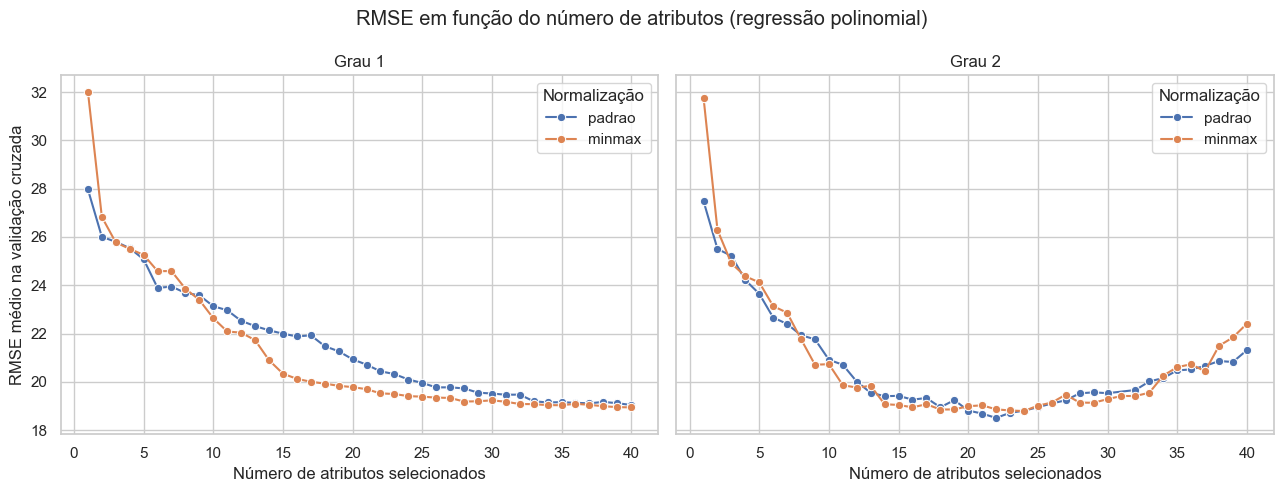

In [69]:
df_linear_rfe = estudo_linear_rfe.trials_dataframe()

fig, eixos = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

for ax, grau in zip(eixos, [1, 2]):
    dados = df_linear_rfe[df_linear_rfe["params_grau_polinomio"] == grau]
    sns.lineplot(
        data=dados,
        x="params_num_atributos",
        y="value",
        hue="params_normalizacao",
        marker="o",
        ax=ax,
    )
    ax.set_title(f"Grau {grau}")
    ax.set_xlabel("Número de atributos selecionados")
    ax.set_ylabel("RMSE médio na validação cruzada")
    ax.legend(title="Normalização")

fig.suptitle("RMSE em função do número de atributos (regressão polinomial)")
plt.tight_layout()
plt.show()

Com o gráfico do RMSE em função do número de atributos selecionados acima, nota-se que, no grau $1$, o RMSE diminui de forma contínua, de cerca de $28\ K$ a $32\ K$ com um atributo para cerca de $19\ K$ com $40$, e a queda desacelera a partir de aproximadamente $30$ atributos. A normalização `MinMaxScaler` foi melhor que a `StandardScaler` entre cerca de $10$ a $25$ atributos, e as duas se aproximam depois disso. No grau $2$, o RMSE atinge um mínimo de cerca de $18.5\ K$ com $22$ atributos e volta a subir para cerca de $21\ K$ a $22\ K$ com $40$, comportamento típico de overfitting, já que o número de atributos polinomiais cresce rapidamente e a regressão não é regularizada. As curvas dos dois graus se cruzam em torno de aproximadamente $28$ a $30$ atributos, onde abaixo disso o grau $2$ se sai melhor e acima o grau $1$ é igual ou melhor. Isso explica a importância baixa do grau no gráfico anterior ($0.02$), visto que o efeito do hiperparâmetro tem sinais opostos conforme o número de atributos, e se cancela na média. 

Agora vamos medir o melhor modelo obtido, no conjunto de teste uma única vez:

In [70]:
modelo_linear_rfe = cria_modelo_linear_rfe(melhor_trial_linear_rfe)
modelo_linear_rfe.fit(X_treino, y_treino)

y_verdadeiro = y_teste
y_previsao = modelo_linear_rfe.predict(X_teste)

RMSE_LINEAR_RFE_TESTE = root_mean_squared_error(y_verdadeiro, y_previsao)

print(f'RMSE da regressão linear polinomial com RFE no conjunto de teste: {RMSE_LINEAR_RFE_TESTE:.2f} K')
print(f'\nRMSE do baseline no conjunto de teste: {RMSE_BASELINE:.2f} K')
print(f'\nRedução no erro: {(1 - (RMSE_LINEAR_RFE_TESTE/RMSE_BASELINE))*100:.2f}%')

RMSE da regressão linear polinomial com RFE no conjunto de teste: 17.30 K

RMSE do baseline no conjunto de teste: 35.50 K

Redução no erro: 51.26%


Analisando o desempenho no conjunto de teste, o pipeline de regressão linear polinomial com RFE otimizado (normalização padrão, RFE com $22$ atributos e polinômio de grau $2$) treinado com todo o conjunto de treino e avaliado uma única no conjunto de teste, obteve RMSE de $17.30\ K$, contra $35.50\ K$ do baseline, uma redução de cerca de $51.3\%$ no erro. Assim como no pipeline 4, o valor é cerca de $1.2\ K$ menor que o RMSE médio da validação cruzada ($18.51\ K$). Nos dois pipelines lineares polinomiais, que geram vários atributos sem regularização, o desempenho no teste foi cerca de $1.2\ K$ melhor que na validação cruzada, enquanto nos demais, a diferença foi de até cerca de $0.6\ K$.

Os pipelines 4 e 5 tiveram desempenhos muito semelhantes ($17.23\ K$ e $17.3\ K$ no teste, $18.43\ K$ e $18.51\ K$ na validação cruzada), de modo que, pra esse problema, selecionar $22$ atributos ou usar $23$ componentes principais é equivalente em desempenho. No entanto, a seleção de atributos tem a vantagem de manter atributos de interpretação direta.

Para finalizar, na célula abaixo será guardado os resultados na tabela feita:

In [71]:
resultados.loc["Regressão linear + RFE + polinômio"] = [melhor_trial_linear_rfe.value, RMSE_LINEAR_RFE_TESTE]
resultados.round(2)

,RMSE validação cruzada,RMSE teste
Baseline,33.96,35.50
KNN + Normalização + PCA,18.92,18.71
Árvore de decisão,18.42,18.94
Floresta aleatória,15.03,14.45
Regressão linear + PCA + polinômio,18.43,17.23
Regressão linear + RFE + polinômio,18.51,17.30


##### **Comparação final**

Vamos analisar os algoritmos/pipelines de forma gráfica na célula abaixo com a tabela ordenada e com um gráfico de barras:

                                    RMSE validação cruzada  RMSE teste
Floresta aleatória                                   15.03       14.45
Árvore de decisão                                    18.42       18.94
Regressão linear + PCA + polinômio                   18.43       17.23
Regressão linear + RFE + polinômio                   18.51       17.30
KNN + Normalização + PCA                             18.92       18.71
Baseline                                             33.96       35.50


[Text(0.5, 0, 'RMSE (K)'),
 Text(0, 0.5, 'Modelo'),
 Text(0.5, 1.0, 'Desempenho dos modelos')]

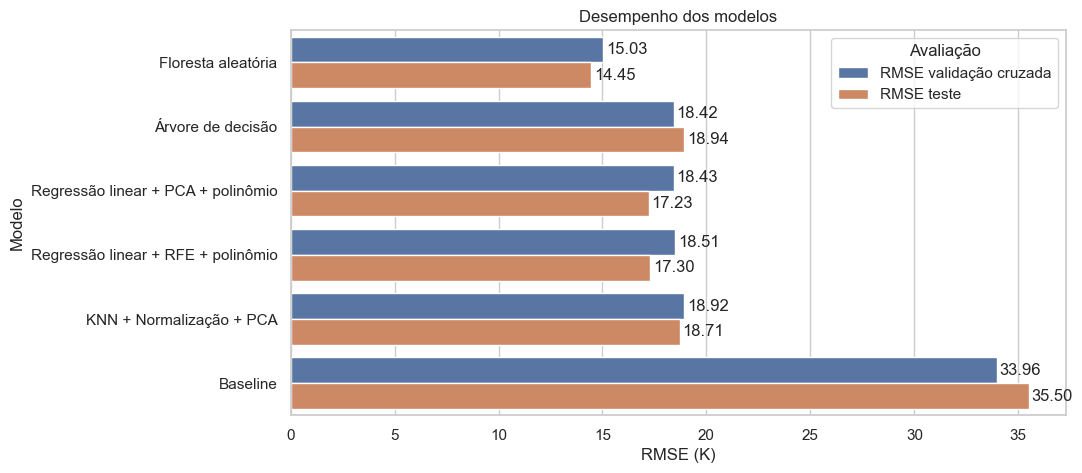

In [72]:
resultados_ordenados = resultados.sort_values("RMSE validação cruzada")
print(resultados_ordenados.round(2))

dados_grafico = (
    resultados_ordenados.rename_axis("Modelo")
    .reset_index()
    .melt(id_vars="Modelo", var_name="Avaliação", value_name="RMSE (K)")
)

fig, eixo = plt.subplots(figsize=(10, 5))

sns.barplot(data=dados_grafico, y="Modelo", x="RMSE (K)", hue="Avaliação", ax=eixo)

for barras in eixo.containers:
    eixo.bar_label(barras, fmt="%.2f", padding=2)
eixo.set(xlabel="RMSE (K)", ylabel="Modelo", title="Desempenho dos modelos")

*OBS.: Gráfico gerado com auxílio do Claude (Anthropic)*

Observando o gráfico acima, que compara o RMSE de validação cruzada e o RMSE no conjunto de teste de todos os algoritmos/pipelines, nota-se que todos eles superam bem o baseline, tanto na validação cruzada, quanto no conjunto de teste. A floresta aleatória foi o melhor algoritmo em ambos protocolos de avaliação ($15.03\ K$ na validação cruzada e $14.45\ K$ no teste), com margem de $3.4\ K$ e $2.8\ K$ sobre o segundo colocado, na validação cruzada e no teste, respectivamente, bem maior que a variação entre folds observada no baseline (cerca de $1\ K$).

Os demais algoritmos/pipelines tiveram desempenho próximo entre si, com RMSE médio de validação cruzada ficando entre $18.42\ K$ e $18.92\ K$, e no teste entre $17.23\ K$ e $18.94\ K$, com mudança na ordem (as regressões lineares polinomiais ficam à frente da árvore e do KNN). Uma hipótese possível para o desempenho superior no modelo da floresta aleatória é que a média de muitas árvores reduz a variância de uma árvore isolada, o que faz sentido ao obsevar overfitting em modelos menos regularizados, mas isso é apenas uma hipótese.

Ainda assim, o melhor modelo tem erro de $14.45\ K$, para uma variável que vai de aproximadamente $0\ K$ até $185\ K$ e tem desvio padrão de cerca de $35\ K$. O erro da floresta equivale a quase $41\%$ do erro do baseline no teste ($14.45\ K$ contra $35.50\ K$), ou seja, uma redução de cerca de $59\%$ (já discutida anteriormente), mas ainda é um erro considerável em termos absolutos, o que sugere que os atributos disponíveis não determinam completamente a temperatura crítica.

Vamos analisar, na célula abaixo, um gráfico de valores reais contra previstos da floresta aleatória para verficar onde o melhor modelo erra:

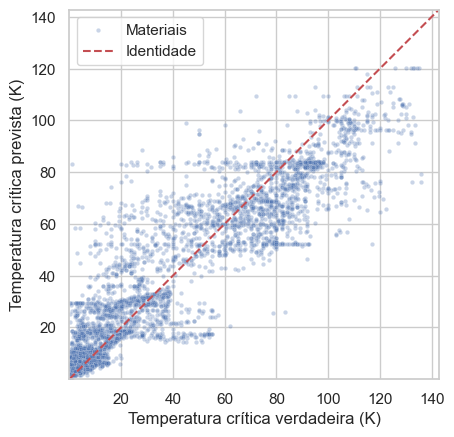

In [73]:
y_previsto_floresta = modelo_floresta.predict(X_teste)

min_val = min(y_teste.min(), y_previsto_floresta.min())
max_val = max(y_teste.max(), y_previsto_floresta.max())

intervalo = [min_val * 0.95, max_val * 1.05]

eixo = sns.scatterplot(x=y_teste, y=y_previsto_floresta, alpha=0.3, s=10, label="Materiais")
eixo.plot(intervalo, intervalo, "r--", label="Identidade")

eixo.set(
    xlabel="Temperatura crítica verdadeira (K)",
    ylabel="Temperatura crítica prevista (K)",
    xlim=intervalo,
    ylim=intervalo,
    aspect="equal",
)
eixo.legend();

*OBS.: Gráfico gerado a partir de uma adaptação de um código feito pelo Prof. Dr. Daniel Roberto Cassar na referência [2].*

Analisando o gráfico de valores reais contra previstos acima, é possível notar que as previsões da floresta acompanham a diagonal de forma geral, com uma maior concentração de pontos nos materiais de baixa temperatura crítica (abaixo de cerca de $20\ K$), em que a maior parte das previsões também é baixa. No entanto, nota-se que, para materiais com $T_c$ verdadeira entre cerca de $60\ K$ e $100\ K$, muitas previsões se concentram em uma faixa horizontal em torno de $80\ K$ a $85\ K$, de modo que os valores mais baixos desse grupo tendem a ser superestimados e os mais altos subestimados. Para materiais com $T_c$ verdadeira entre cerca de $40\ K$ e $60\ K$, há uma faixa de previsões um pouco abaixo de $20\ K$, bem abaixo do valor real, e os valores mais altos (acima de cerca de $110\ K$) tendem a ser subestimados. Observam-se também alguns erros grandes, como materiais com $T_c$ de poucos kelvin previstos com cerca de $60\ K$ a $80\ K$, que, por contribuírem ao quadrado no RMSE, pesam bastante no erro final. Isso pode ser explicado pelo fato da floresta aleatória fazer a média das previsões de todas as árvores individuais, o que tende a aproximar as previsões extremas de valores intermediários. As faixas horizontais e os erros grandes sugerem que o modelo atribui valores típicos de materiais parecidos do treino a grupos de materiais com atributos semelhantes.

##### **Permutation importance no modelo da floresta**

A floresta aleatória foi o melhor algoritmo treinado, mas, diferentemente de uma única árvore de decisão, não pode ser interpretada diretamente por combinar $172$ árvores (melhor modelo). Para entender em que o modelo se baseia para prever a temperatura crítica, usamos a `permutation importance` (importância por permutação) [10, 11], uma técnica que pode ser aplicada a qualquer modelo já treinado.

**Como a `permutation importance` funciona:**

Primeiramente, mede-se o RMSE do modelo já treinado em um conjunto de dados, que serve de linha de base. Depois, embaralham-se aleatoriamente os valores de uma coluna (atributo), o que rompe a relação entre esse atributo e o alvo e mantém todas as demais colunas intactas. Em seguida, mede-se o RMSE novamente, e a importância do atributo é o aumento do RMSE em relação à linha de base, onde se o modelo dependia do atributo, o erro aumenta bastante, e se não, o erro quase não muda. Esse processo é repetido várias vezes (no caso deste algoritmo, $5$), com embaralhamentos diferentes, e reportamos a média e o desvio padrão.

A importância pode ser calculada no treino ou em um conjunto separado. Usar dados que o modelo não viu destaca os atributos que contribuem para a capacidade de generalização, enquanto no treino ela também refletiria o que o modelo memorizou [10]. Por isso utilizaremos o conjunto de teste, o qual será usado apenas para explicar o modelo já escolhido.

**Atributos correlacionados e importância por grupo**

Como os atributos do nosso conjunto de dados apresentam forte multicolinearidade (VIF acima de 10 em todos), a importância de cada atributo isolado tende a ser subestimada, visto que, na técnica, quando dois atributos são correlacionados e um deles é embaralhado, o modelo ainda tem acesso à informação por meio de outro [12]. Por esse motivo, será calculada, além da importância individual, a importância por grupos, onde as $10$ estatísticas de cada propriedade atômica (média, desvio padrão, amplitude etc.) são embaralhadas juntas (com a mesma permutação das linhas), de modo que o grupo mantém sua coerência interna e perde a relação com o alvo. O atributo `number_of_elements` forma um grupo próprio. 

*OBS.: A importância por permutação descreve em que o modelo se baseia, e não necessariamente o que causa a temperatura crítica, e uma importância baixa não significa que o atributo seja irrelevante, já que a informação pode estar contida em atributos correlacionados.*

Com isso, vamos analisar a importância individual de cada atributo:

In [74]:
NUM_REPETICOES = 5

resultado_permutacao = permutation_importance(
    modelo_floresta,
    X_teste,
    y_teste,
    scoring="neg_root_mean_squared_error",
    n_repeats=NUM_REPETICOES,
    random_state=SEMENTE_ALEATORIA,
)

importancias = pd.DataFrame({
    "atributo": ATRIBUTOS,
    "media": resultado_permutacao.importances_mean,
    "desvio": resultado_permutacao.importances_std,
}).sort_values("media", ascending=False)

top15 = importancias.head(15)

Na célula abaixo, será plotado um gráfico (gerado com auxílio do Claude) dos 15 atributos mais importantes (importância por permutação):

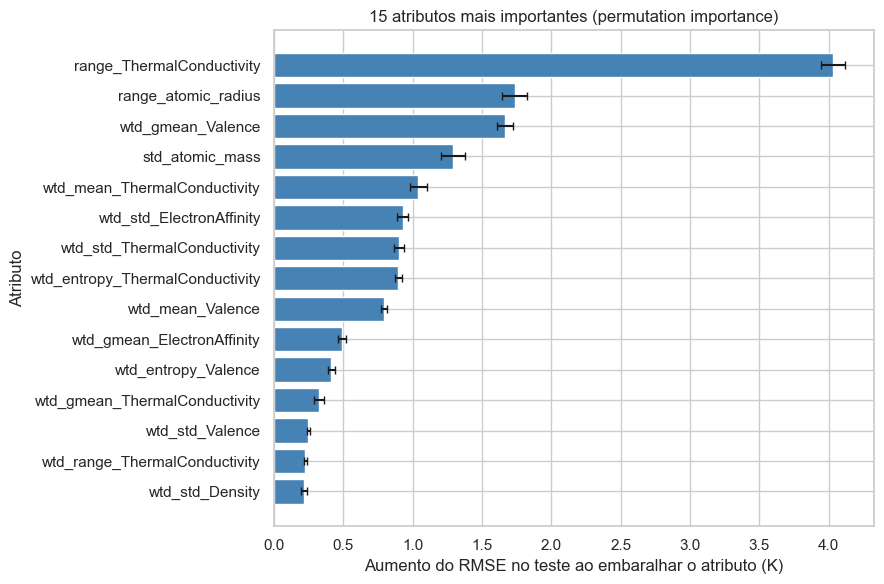

In [75]:
# Inverte a ordem para o atributo mais importante ficar no topo
top15_ordenado = top15.iloc[::-1]

fig, ax = plt.subplots(figsize=(9, 6))

ax.barh(
    top15_ordenado["atributo"],
    top15_ordenado["media"],
    xerr=top15_ordenado["desvio"],
    capsize=3,
    color="steelblue",
)

ax.set_xlabel("Aumento do RMSE no teste ao embaralhar o atributo (K)")
ax.set_ylabel("Atributo")
ax.set_title("15 atributos mais importantes (permutation importance)")

plt.tight_layout()
plt.show()

Observando a importância individual acima, é possível notar que o atributo mais relevante para o modelo é `range_ThermalConductivity`, cujo embaralhamento aumenta o RMSE no teste em cerca de $4\ K$, mais que o dobro do segundo colocado (`range_atomic_radius`, com cerca de $1.7\ K$). Os outros atributos têm importâncias bem menores (a partir do $10º$, inferiores a $0.5\ K$), o que indica que o modelo distribui sua dependência entre vários atributos. Entre os $15$ mais importantes, seis são estatísticas da condutividade térmica e quatro da valência, e doze são estatísticas ponderadas (`wtd_`). As barras de erro, que representam o desvio padrão entre as $5$ repetições, são pequenas, de modo que as estimativas aparentam ser estáveis.

Uma coisa interessante é que cinco dos dez atributos mais correlacionados com o alvo na análise exploratória aparecem nessa lista (`range_ThermalConductivity`, `range_atomic_radius`, `wtd_mean_Valence`, `wtd_gmean_Valence` e
`wtd_std_ThermalConductivity`), mas os outros cinco não (`std_ThermalConductivity`, `wtd_entropy_atomic_mass`,
`wtd_entropy_atomic_radius`, `number_of_elements` e `range_fie`), o que mostra que a correlação com o alvo não significa dependência do modelo, principalmente entre atributos redundantes. Como os atributos são muito correlacionados, a importância de cada um isoladamente tende a ser subestimada, o que motiva a análise por grupos que será feita a seguir.

Vamos analisar a importância por grupos:

In [76]:
propriedades = [
    "ThermalConductivity", "Valence", "ElectronAffinity", "atomic_mass",
    "atomic_radius", "Density", "fie", "FusionHeat", "number_of_elements",
] # Propriedades atômicas + número de elementos

X_teste_df = pd.DataFrame(X_teste, columns=ATRIBUTOS)
rmse_original = root_mean_squared_error(y_teste, modelo_floresta.predict(X_teste))

linhas = []
for prop in propriedades:
    colunas_do_grupo = [nome for nome in ATRIBUTOS if nome.endswith(prop)]

    aumentos = []
    for repeticao in range(NUM_REPETICOES):
        X_embaralhado = X_teste_df.copy()
        # Embaralhando as linhas das colunas do grupo
        X_embaralhado[colunas_do_grupo] = X_teste_df[colunas_do_grupo].sample(frac=1, random_state=repeticao).values
        rmse_embaralhado = root_mean_squared_error(y_teste, modelo_floresta.predict(X_embaralhado.values))
        aumentos.append(rmse_embaralhado - rmse_original)
    
    linhas.append((prop, np.mean(aumentos), np.std(aumentos)))

importancia_grupos = pd.DataFrame(linhas, columns=["propriedade", "media", "desvio"]).sort_values("media", ascending=False)
importancia_grupos.round(2)

,propriedade,media,desvio
0,ThermalConductivity,10.12,0.10
1,Valence,6.50,0.09
2,ElectronAffinity,2.66,0.03
4,atomic_radius,2.29,0.04
3,atomic_mass,2.18,0.04
5,Density,1.10,0.03
7,FusionHeat,0.54,0.02
6,fie,0.49,0.02
8,number_of_elements,-0.00,0.00


Na célula abaixo, será plotado um gráfico (gerado com auxílio do Claude) da importância por permutação em grupos:

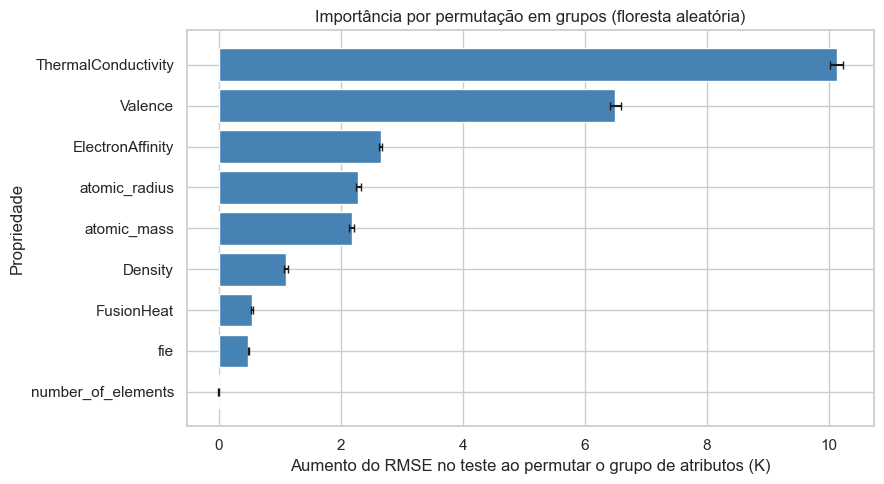

In [77]:
# Inverte a ordem para a propriedade mais importante ficar no topo
dados = importancia_grupos.iloc[::-1]

fig, ax = plt.subplots(figsize=(9, 5))

ax.barh(
    dados["propriedade"],
    dados["media"],
    xerr=dados["desvio"],
    capsize=3,
    color="steelblue",
)

ax.set_xlabel("Aumento do RMSE no teste ao permutar o grupo de atributos (K)")
ax.set_ylabel("Propriedade")
ax.set_title("Importância por permutação em grupos (floresta aleatória)")

plt.tight_layout()
plt.show()

Analisando a importância por grupo no gráfico e na tabela acima, nota-se que o modelo depende principalmente de duas propriedades, onde embaralhar as dez estatísticas da condutividade térmica aumenta o RMSE no teste em cerca de $10.1\ K$ (vai de $14.45\ K$ para $\sim 24.6\ K$) e embaralhar as da valência aumenta o RMSE em cerca de $6.5\ K$ (pra $\sim 20.9\ K$). Em seguida vem a afinidade eletrônica ($\sim 2.7\ K$), o raio atômico ($\sim 2.3\ K$) e a massa atômica ($\sim 2.2\ K$), com importância semelhante, e, por fim, a densidade ($1.1\ K$), o calor de fusão ($\sim 0.5\ K$) e a primeira energia de ionização ($\sim 0.5\ K$). A importância do atributo `number_of_elements` foi nula, o que não significa que seja irrelevante, visto que a importância dele provavelmente está contida em outros atriutos.

Ao comparar com a importância individual, a de cada grupo é bem maior que a de seu melhor atributo isolado, por exemplo, o grupo da condutividade térmica (cerca de $10.1\ K$) vale mais que o dobro do atributo individual mais importante (`range_ThermalConductivity`, $\sim 4.0\ K$), e o grupo da valência (cerca de $6.5\ K$) vale bem mais que o triplo do melhor atributo do grupo (`wtd_gmean_Valence`, $\sim 1.7\ K$). Isso confirma que a informação de cada propriedade está distribuída entre suas estatísticas redundantes, e que a análise individual subestima a dependência do modelo. O resultado também bate com a análise exploratória feita, na qual os atributos mais correlacionados com a temperatura crítica eram, na maioria, da condutividade térmica e da valência.

Em síntese, o modelo da flroesta baseia suas previsões principalmente na variação da condutividade térmica e da valência entre os elementos do material. Como a `permutation importance` descreve em que o modelo se apoia, e não o que causa a supercondutividade, esses resultados não permitem concluir uma relação física entre essas propriedades e a temperatura crítica, mas indicam quais atributos merecem maior atenção.

## **Conclusões e principais aprendizados**

Finalmente concluímos a captura do dragão lendário Tiamat. Para isso, foi estudado o conjunto de dados `Superconductivity Data`, com $21197$ materiais supercondutores (depos de remover as $66$ linhas duplicadas) descritos por $81$ atributos derivados da composição química, com o objetivo de prever a temperatura crítica ($T_c$) de cada material. Foram treinados $5$ algoritmos/pipelines, cada um com pelo menos $100$ conjuntos diferentes de hiperparâmetros avaliados com o `optuna`, sendo eles KNN com normalização e PCA, árvore de decisão, floresta aleatória, e duas regressões lineares com atributos polinomiais, uma com PCA e outra com seleção de atributos por RFE. Todos foram comparados a um modelo baseline que prevê sempre a média do treino (RMSE de $35.50\ K$ no teste).

Como materiais da mesma família química têm atributos quase idênticos, um split aleatório faria "primos" caírem no treino e no teste e deixaria o erro baixo (vazamento de dados por redundância). A estratégia de arredondar atributos e agrupar linhas iguais, vista em aula, não funcionou aqui ($15089$ grupos para $21197$ materiais, quase um por material), e por isso os grupos foram criados com `KMeans` ($500$ grupos) e usados tanto na divisão treino/teste (`GroupShuffleSplit`) quanto na validação cruzada (`GroupKFold`). O conjunto de teste foi usado uma única vez para cada pipeline, depois da otimização, e nenhuma decisão dependeu dele.

Com relação aos resultados, a floresta aleatória foi o melhor algoritmo tanto na validação cruzada (RMSE de $15.03\ K$) quanto no teste (RMSE de $14.45\ K$), e apresentou uma redução de aproximadamente $59\%$ no erro ao comparar com o baseline. Os outros quatro algoritmos/pipelines tiveram desempenho parecido entre si (validação cruzada entre $18.42\ K$ e $18.92\ K$, e teste entre $17.23\ K$ e $18.94\ K$) e trocaram de ordem entre os protocolos de avaliação, de modo que não é possível ordená-los com segurança. Chama atenção que as regressões lineares com termos polinomiais, que são modelos lineares nos parâmetros, tenham ficado no mesmo patamar da árvore e do KNN, e que usar $23$ componentes do PCA ou $22$ atributos selecionados pelo RFE tenha rendido praticamente o mesmo, o que mostra a redundância entre os atributos. Uma hipótese formada no decorrer desta atividade para o desempenho superior da floresta é que a média de muitas árvores reduz a variância de uma árvore isolada, mas essa hipótese não foi testada.

Analisando o gráfico de reais contra previstos, nota-se que mesmo o melhor modelo apresenta limitações claras. O gráfico mostrou que a floresta tende a aproximar as previsões de valores intermediários (superestimando materiais de $T_c$ baixa dentro de um grupo e subestimando os de $T_c$ muito alta, acima de $110\ K$), além de alguns erros grandes isolados. O erro de $14.45\ K$ equivale a cerca de $41\%$ do erro do baseline, mas ainda é considerável para uma variável com desvio padrão de cerca de $35\ K$, o que sugere que os atributos disponíveis não determinam completamente a temperatura crítica. Para entender no que o modelo da floresta se apoia para realizar as previsões foi utilizado `permutation importance` e notou-se que embaralhar as dez estatísticas da condutividade térmica aumentou o RMSE no teste em cerca de $10.1\ K$, e as da valência em cerca de $6.5\ K$, muito acima das demais propriedades. A análise por grupos foi essencial, visto que a importância dos atributos isolados (no máximo cerca de $4\ K$) subestimava a dependência do modelo devido à forte multicolinearidade. Esse resultado descreve em que o modelo se baseia, e não necessariamente o que causa a supercondutividade.

No decorrer da realização deste trabalho foram aprendidas lições práticas sobre os hiperparâmetros. O número de vizinhos do KNN e a profundidade das árvores reproduziram a relação entre viés e variância aprendida na aula, onde valores muito pequenos pioraram o RMSE (overfitting no KNN e underfitting na árvore). Nas regressões polinomiais, o RMSE formou um "U" no gráfico em função das dimensões, com mínimo em torno de $20$ a $25$ dimensões (overfitting de uma regressão não regularizada quando os atributos polinomiais se multiplicam), e a importância do grau do polinômio foi baixa no RFE pois seu efeito muda de sinal conforme o número de atributos. Em árvores, vários hiperparâmetros limitam a complexidade do modelo de formas equivalentes (a melhor árvore foi limitada pelo número de folhas, e a profundidade nem chegou a atuar). Também vi o peso computacional na escolha do espaço de busca, no qual, por exemplo, a potência de Minkowski contínua tornava cada tentativa do KNN cerca de $30$ vezes mais lenta ($45\ s$ contra $1.5\ s$), e por isso foi restringida a $1$ ou $2$, e a floresta aleatória levou cerca de $50$ minutos para ser otimizada, enquanto a árvore de decisão levou apenas cerca de $1$ minuto.

De forma geral, a captura do Tiamat foi muito útil para aumentar meus pontos de inteligência e experiência, pois pude praticar o planejamento de um projeto de aprendizado de máquina ao entender e explorar os dados, evitar vazamentos, definir um protocolo de avaliação, otimizar hiperparâmetros de vários algoritmos, compará-los com um baseline e interpretar o modelo. Agora me sinto capaz de enfrentar monstros de múltiplas cabeças com mais segurança.

## **Descrição do uso de IA neste trabalho**

Durante a realização deste trabalho, utilizei o Claude (Anthropic) como apoio em diferentes etapas. Primeiro, o usei para avaliar se o conjunto de dados que eu havia encontrado atendia aos critérios do enunciado e para entender como os $81$ atributos foram construídos (propriedades atômicas $\times$ estatísticas). A partir dessa conversa, também discuti o vazamento de dados por materiais idênticos ou muito parecidos, o que me levou a testar o agrupamento por arredondamento e, depois, a adotar o `KMeans` com `GroupShuffleSplit` e `GroupKFold`. A escolha do dataset, do $K = 500$ e dos pipelines (incluindo a ideia de combinar PCA ou RFE com termos polinomiais) foram decisões minhas. Além disso, o Claude explicou o funcionamento de conceitos que eu não dominava, como `KMeans`, `permutation importance` (incluindo a versão em grupos, para lidar com atributos correlacionados) e `GridSampler`, e me indicou a documentação oficial para eu estudar. Em relação ao código, o Claude gerou versões iniciais que eu adaptei e conferi em algumas células, todas indicadas ao longo do notebook (o histograma do target, a contagem de pares de atributos correlacionados, o teste de tempo do `optuna`, os gráficos de dispersão do RMSE em função dos hiperparâmetros (PCA e floresta aleatória), o gráfico de linhas das regressões polinomiais, o gráfico de barras da comparação final e os gráficos da importância por permutação). As funções que criam os pipelines e as funções objetivo seguem os notebooks do professor [9], com adaptações minhas, e o código da importância por permutação em grupos foi escrito por mim. Também pedi ao Claude opiniões sobre os intervalos de hiperparâmetros, o que levou, por exemplo, a restringir a potência de Minkowski do KNN a $1$ ou $2$ depois de eu confirmar a hipótese de lentidão com um teste de tempo. Usei ainda o Claude para revisar minhas análises e a redação (por exemplo, ao apontar pontos que eu não havia comentado no gráfico de valores reais contra previstos e ao sugerir reformulações, das quais adaptei trechos) e, ao final, para avaliar o notebook inteiro com base no enunciado, o que apontou erros pontuais que corrigi. Nessa revisão, o Claude também recalculou alguns resultados para conferir os números do notebook. Todos os resultados apresentados vêm das execuções do meu próprio notebook, e a interpretação e a redação final dos textos são minhas, com os trechos mencionados acima tendo ajuda da IA.

*Link da conversa com a IA:* https://claude.ai/share/3c52ce49-77ec-4f3a-8871-cf99a4fd695d

Durante a realização deste trabalho, utilizei, também, as respostas geradas pela IA diretamente por pesquisas no Google (Gemini) como apoio técnico e conceitual. A ferramenta auxiliou no embaralhamento de colunas na `permutation importance` em grupos com `.sample(frac=1)`, na definição do número ideal de `n_jobs` para otimizações no `optuna` considerando o processador Intel Core Ultra 5 125U, no uso do método `.endswith()` para seleção de sufixos em strings e na compreensão teórica sobre regressões lineares regularizadas. Além disso, serviu de suporte para a aplicação de `np.triu` no mascaramento de matrizes de correlação, para a remoção de rótulos dos eixos em heatmaps do `seaborn` usando `xticklabels=False` e `yticklabels=False`, e para o cálculo da assimetria dos dados por meio do método `.skew()` do pandas.

## **Referências**

Hamidieh, K. (2018). **Superconductivty Data [Dataset]**. UCI Machine Learning Repository. https://doi.org/10.24432/C53P47. [1]

CASSAR, Daniel Roberto. **ATP-203 3.0 - Modelo linear e baseline** [2]

CASSAR, Daniel Roberto. **ATP-203 8.0 - Redução de dimensionalidade com PCA** [3]

CASSAR, Daniel Roberto. **ATP-203 8.1 - Seleção de atributos** [4]

CASSAR, Daniel Roberto. **ATP-203 6.1 - Vazamento de dados** [5]

KMeans https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html [6]

Validação cruzada em grupos https://scikit-learn.org/stable/modules/cross_validation.html#group-k-fold [7]

Validação cruzada em grupos https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupKFold.html [8]

CASSAR, Daniel Roberto. **ATP-203 7.1 - Otimização de hiperparâmetros com optuna** [9]

Permutation importance https://scikit-learn.org/stable/modules/permutation_importance.html [10]

Permutation importance https://scikit-learn.org/stable/modules/generated/sklearn.inspection.permutation_importance.html [11]

Permutation importance em atributos correlacionados https://scikit-learn.org/stable/auto_examples/inspection/plot_permutation_importance_multicollinear.html#sphx-glr-auto-examples-inspection-plot-permutation-importance-multicollinear-py [12]

*Mais notebooks utilizados como referência:*

CASSAR, Daniel Roberto. **ATP-203 1.1 - Tratamento de dados com pandas**

CASSAR, Daniel Roberto. **ATP-203 2.1 - Aprendizado de máquina, k-NN e métricas**

CASSAR, Daniel Roberto. **ATP-203 2.2 - Divisão de dados em treino e teste**

CASSAR, Daniel Roberto. **ATP-203 4.0 - Árvore de decisão e floresta aleatória**

CASSAR, Daniel Roberto. **ATP-203 6.0 - Validação cruzada e otimização de hiperparâmetros**

CASSAR, Daniel Roberto. **ATP-203 7.0 - Dados sintéticos e pipeline**